# Lecture 1 · KL divergence, variational inference and the ELBO

[▶ Open in Colab](https://colab.research.google.com/github/nipunbatra/generative/blob/main/lectures/lecture1/lecture1-variational-inference.ipynb) · [Slides](https://nipunbatra.github.io/generative/lectures/lecture1/) · ES 667 Deep Learning, IIT Gandhinagar

This notebook computes every number, figure and animation in the Lecture 1 slides, **in the same order and with the same section numbers**. Each section starts with a link to its slides, and every slide has a **▶ Notebook** link in its top-right corner that jumps to the matching section here.

**How to use it.** Run everything once (*Runtime → Run all* in Colab, or *Run → Run All Cells* in Jupyter); cells build on earlier ones, so always run from the top. Then jump around with the table of contents in the left sidebar. CPU only, about three minutes.

| Part | Sections |
|---|---|
| **1 · Bayes’ rule for a neural network** | [1.1 Bayes’ rule](https://nipunbatra.github.io/generative/lectures/lecture1/#bayes-rule/1) · [1.2 A tiny network and its prior](https://nipunbatra.github.io/generative/lectures/lecture1/#tiny-net/1) · [1.3 Likelihood and training](https://nipunbatra.github.io/generative/lectures/lecture1/#data-likelihood/1) · [1.4 The evidence is intractable](https://nipunbatra.github.io/generative/lectures/lecture1/#evidence-area/1) · [1.5 Approximating the posterior](https://nipunbatra.github.io/generative/lectures/lecture1/#predictive/1) |
| **2 · How far apart are two distributions?** | [2.1 Surprise](https://nipunbatra.github.io/generative/lectures/lecture1/#surprise-forecast/1) · [2.2 Entropy](https://nipunbatra.github.io/generative/lectures/lecture1/#entropy-average/1) · [2.3 Codes](https://nipunbatra.github.io/generative/lectures/lecture1/#channel/1) · [2.4 Cross-entropy and KL](https://nipunbatra.github.io/generative/lectures/lecture1/#wrong-belief/1) · [2.5 Classification loss](https://nipunbatra.github.io/generative/lectures/lecture1/#classifier/1) · [2.6 Maximum likelihood](https://nipunbatra.github.io/generative/lectures/lecture1/#mle-data/1) · [2.7 KL at work: distillation and RLHF](https://nipunbatra.github.io/generative/lectures/lecture1/#kl-everywhere/1) · [2.8 Closed forms and PyTorch](https://nipunbatra.github.io/generative/lectures/lecture1/#densities/1) · [2.9 KL by sampling](https://nipunbatra.github.io/generative/lectures/lecture1/#kl-expectation/1) |
| **3 · Find the closest q** | [3.1 Search a grid](https://nipunbatra.github.io/generative/lectures/lecture1/#six-candidates/1) · [3.2 Gradient descent](https://nipunbatra.github.io/generative/lectures/lecture1/#walk-downhill/1) · [3.3 Covariance in 2-D](https://nipunbatra.github.io/generative/lectures/lecture1/#cov-families/1) · [3.4 Mixtures: no formula](https://nipunbatra.github.io/generative/lectures/lecture1/#mixture-what/1) · [3.5 The reparameterisation trick](https://nipunbatra.github.io/generative/lectures/lecture1/#missing-path/1) · [3.6 Which direction of KL?](https://nipunbatra.github.io/generative/lectures/lecture1/#fwdrev/1) |
| **4 · Back to Bayes: the ELBO** | [4.1 Deriving the ELBO](https://nipunbatra.github.io/generative/lectures/lecture1/#can-we/1) · [4.2 Checking it on a coin](https://nipunbatra.github.io/generative/lectures/lecture1/#elbo-slider/1) |
| **5 · Implement it** | [5.1 VI for the tiny network](https://nipunbatra.github.io/generative/lectures/lecture1/#bnn-elbo-code/1) · [5.2 Wrap-up](https://nipunbatra.github.io/generative/lectures/lecture1/#five-tools/1) |
| Appendix | [KL by hand: grades in two runs of a course](https://nipunbatra.github.io/generative/lectures/lecture1/?all#grades/1) |

Links in the table open the slides. **Notation:** natural logarithms throughout, so KL is in nats. `Normal(loc=μ, scale=σ)` takes a **standard deviation**; the maths writes $\mathcal N(\mu,\sigma^2)$. $\theta$ is the unknown (our network’s seven parameters, or one number in the toy examples), $\mathcal D$ the data, $q$ our approximation and $\psi$ its parameters.

In [1]:
from pathlib import Path
import json, math, platform
import numpy as np
import torch
from torch import distributions as dist
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.manual_seed(20261020)
np.random.seed(20261020)
OUT = Path.cwd()
for folder in ["figures", "data", "qa"]:
    (OUT / folder).mkdir(exist_ok=True)

C = dict(p="#0F766E", q="#8B2CDE", data="#245EDB", noise="#AA4E08", loss="#BE123C")
plt.rcParams.update({
    "font.family": ["Avenir Next", "Arial", "DejaVu Sans", "sans-serif"],
    "font.size": 19, "axes.titlesize": 21,
    "axes.labelsize": 19, "xtick.labelsize": 17, "ytick.labelsize": 17,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "#FAFAFB", "axes.facecolor": "#FAFAFB",
    "svg.fonttype": "none", "lines.linewidth": 2.5,
})
fixtures = {"provenance": {
    "seed": 20261020, "dtype": "torch.float64", "torch": torch.__version__,
    "python": platform.python_version(), "numpy": np.__version__,
    "evidence": "computed locally; analytic, quadrature and Monte Carlo outputs labelled separately",
    "source_spine": "PML 2023 variational-inference.ipynb; corrected standalone implementation",
}}
def number(x): return float(x.detach()) if isinstance(x, torch.Tensor) else float(x)
def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / "figures" / f"{name}.svg", bbox_inches="tight")
    plt.savefig(OUT / "figures" / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
def normal_kl(q, p):
    return torch.log(p.scale/q.scale) + (q.scale.square() + (q.loc-p.loc).square())/(2*p.scale.square()) - .5
print("CPU; float64; PyTorch", torch.__version__, "· fixed seeds recorded per experiment")

CPU; float64; PyTorch 2.13.0 · fixed seeds recorded per experiment


## Part 1 · Bayes’ rule for a neural network

Slides: [Part 1](https://nipunbatra.github.io/generative/lectures/lecture1/#bayes-rule/1). A tiny network, its prior, its likelihood, an evidence we cannot compute, and why we want the posterior anyway.

### 1.1 Bayes’ rule

Slides: [1.1 Bayes’ rule](https://nipunbatra.github.io/generative/lectures/lecture1/#bayes-rule/1)

For model parameters $\theta$ and training data $\mathcal D$:

$$\underbrace{p(\theta\mid\mathcal D)}_{\text{posterior}}=\frac{\overbrace{p(\mathcal D\mid\theta)}^{\text{likelihood}}\ \overbrace{p(\theta)}^{\text{prior}}}{\underbrace{p(\mathcal D)}_{\text{evidence}}}.$$

Usual training keeps one $\theta$, the best fit. Bayesian learning keeps every $\theta$, weighted by the posterior.

### 1.2 A tiny network and its prior

Slides: [1.2 A tiny network and its prior](https://nipunbatra.github.io/generative/lectures/lecture1/#tiny-net/1) · [one draw is one function](https://nipunbatra.github.io/generative/lectures/lecture1/#one-draw/1) · [twenty draws](https://nipunbatra.github.io/generative/lectures/lecture1/#prior-functions/1)

One input, two tanh hidden units, one output:

$$f_\theta(x)=v_1\tanh(w_1x+b_1)+v_2\tanh(w_2x+b_2)+c,\qquad\theta=(w_1,w_2,b_1,b_2,v_1,v_2,c)\in\mathbb R^7.$$

**Prior:** every parameter independently $\mathcal N(0,1)$. One draw of $\theta$ is seven numbers, and putting them into the network gives one whole function. Averaging over many draws, with the observation noise added, gives the **prior predictive**.

first draw θ⁽¹⁾: [0.79, 1.39, -0.15, -0.02, 0.28, -1.1, -1.03]
prior predictive sd at x = −2.5, 0, 2.5: [1.54, 1.33, 1.55]


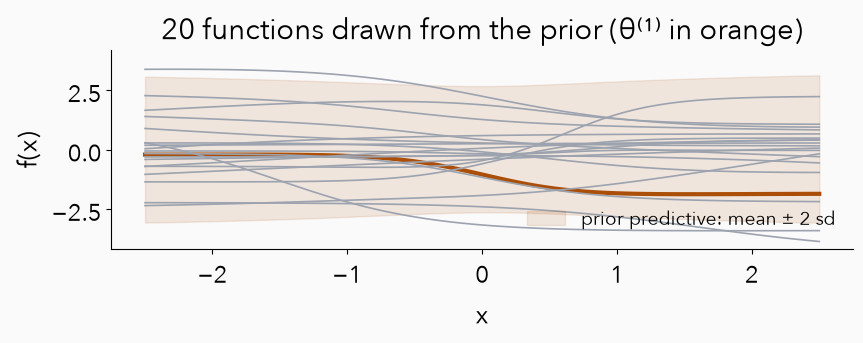

In [2]:
bnn_names = ["w1", "w2", "b1", "b2", "v1", "v2", "c"]
def net(theta, x):
    # theta [..., 7] and inputs x [N] give outputs [..., N]
    w, b, v, c = theta[..., 0:2], theta[..., 2:4], theta[..., 4:6], theta[..., 6:7]
    hidden = torch.tanh(w[..., None, :] * x[:, None] + b[..., None, :])
    return (hidden * v[..., None, :]).sum(-1) + c
noise_sd = 0.1  # the observation noise of the model, y ~ N(f(x), 0.1²); known
theta_prior = dist.Normal(torch.zeros(7), torch.ones(7))
x_grid = torch.linspace(-2.5, 2.5, 121)
torch.manual_seed(12)
prior_draws = theta_prior.sample((20,))
# The prior predictive: average over many prior draws, then add the observation noise
torch.manual_seed(15)
F_prior = net(theta_prior.sample((4000,)), x_grid)
prior_predictive = dict(draws=4000, mean=F_prior.mean(0).tolist(), sd_f=F_prior.std(0).tolist(),
                        sd=(F_prior.var(0) + noise_sd ** 2).sqrt().tolist())
fixtures["story"] = {"bnn": dict(names=bnn_names, prior=[0., 1.], grid=x_grid.tolist(),
    prior_draws=net(prior_draws, x_grid).tolist(), prior_thetas=prior_draws.tolist(),
    prior_predictive=prior_predictive)}
print("first draw θ⁽¹⁾:", [round(v, 2) for v in prior_draws[0].tolist()])
print("prior predictive sd at x = −2.5, 0, 2.5:", [round(prior_predictive["sd"][i], 2) for i in (0, 60, 120)])
fig, ax = plt.subplots(figsize=(8.8, 3.8))
mean, sd = np.array(prior_predictive["mean"]), np.array(prior_predictive["sd"])
ax.fill_between(x_grid, mean - 2 * sd, mean + 2 * sd, color=C["noise"], alpha=.12, label="prior predictive: mean ± 2 sd")
for k, f_draw in enumerate(net(prior_draws, x_grid)):
    ax.plot(x_grid, f_draw, color=C["noise"] if k == 0 else "#9CA3AF", lw=3 if k == 0 else 1.2)
ax.set(xlabel="x", ylabel="f(x)", ylim=(-4.2, 4.2), title="20 functions drawn from the prior (θ⁽¹⁾ in orange)")
ax.legend(frameon=False, fontsize=14, loc="lower right")
savefig("bnn-prior-predictive")

### 1.3 The likelihood, and training one network: $\theta_A$

Slides: [1.3 Likelihood and training](https://nipunbatra.github.io/generative/lectures/lecture1/#data-likelihood/1) · [training animation](https://nipunbatra.github.io/generative/lectures/lecture1/#map-train/1) · [meet θ_A](https://nipunbatra.github.io/generative/lectures/lecture1/#theta-a/1) · [two settings of θ](https://nipunbatra.github.io/generative/lectures/lecture1/#two-thetas/1)

Seventeen training points with a gap in the middle. **Likelihood:** $y_i\mid x_i,\theta\sim\mathcal N\big(f_\theta(x_i),0.1^2\big)$, independently, so $p(\mathcal D\mid\theta)=\prod_i\mathcal N\big(y_i;f_\theta(x_i),0.1^2\big)$.

$\theta_A$ maximises $\log p(\mathcal D\mid\theta)+\log p(\theta)$: squared error divided by $2\cdot0.1^2$, plus $\tfrac12\|\theta\|^2$ (weight decay). Ten random starts of Adam; the best finish is $\theta_A$, the MAP estimate. $\theta_B$ is one random draw from the prior, for comparison.

final objective of the ten starts: [14.83, 14.34, 14.34, 14.34, 15.47, 14.35, 14.34, 14.34, 14.34, 14.34] · best seed 8
theta A, the MAP: log p(D|θ) = 12.17, log p(θ) = -9.41
theta B, a prior draw: log p(D|θ) = -2157.52, log p(θ) = -9.89


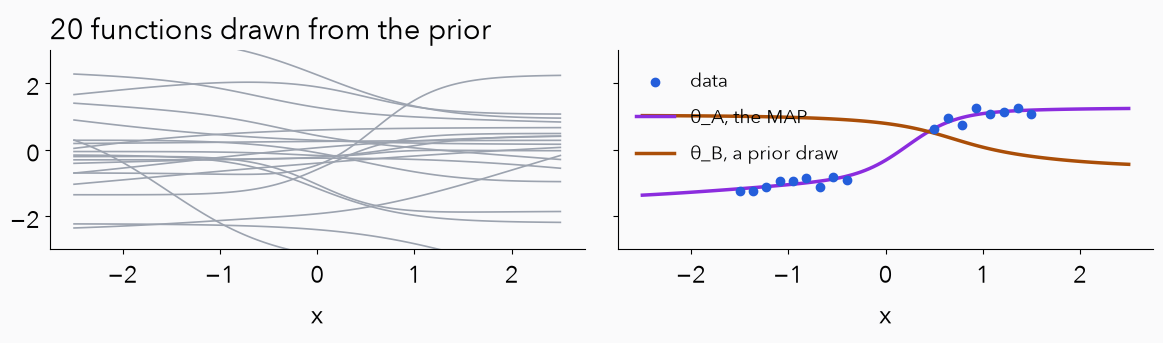

In [3]:
torch.manual_seed(7)
x_train = torch.cat([torch.linspace(-1.5, -0.4, 9), torch.linspace(0.5, 1.5, 8)])
noise_sd = 0.1
y_train = 0.8 * torch.tanh(3 * x_train) + 0.3 * x_train + noise_sd * torch.randn(len(x_train))
def bnn_log_lik(theta):
    return dist.Normal(net(theta, x_train), noise_sd).log_prob(y_train).sum(-1)
def bnn_log_prior(theta):
    return theta_prior.log_prob(theta).sum(-1)
def bnn_log_joint(theta):
    return bnn_log_lik(theta) + bnn_log_prior(theta)
# theta_A: the most probable parameters (MAP), best of ten restarts. theta_B: one draw from the prior.
def map_objective(theta):
    # −log p(D|θ) − log p(θ) without its constants: squared error / (2·0.1²) + ½‖θ‖², i.e. weight decay
    return ((y_train - net(theta, x_train)) ** 2).sum(-1) / (2 * noise_sd ** 2) + (theta ** 2).sum(-1) / 2
best, map_runs = None, []
for seed in range(10):
    torch.manual_seed(seed)
    th = torch.nn.Parameter(torch.randn(7))
    opt_map = torch.optim.Adam([th], lr=.05)
    path = []
    for step in range(2000):
        if step % 10 == 0:
            path.append(th.detach().clone())
        loss = -bnn_log_joint(th)
        opt_map.zero_grad(); loss.backward(); opt_map.step()
    path.append(th.detach().clone())  # after the last update, step 2000
    map_runs.append(torch.stack(path))
    if best is None or number(loss) < best[0]:
        best = (number(loss), th.detach().clone(), seed)
theta_A, best_seed = best[1], best[2]
assert torch.equal(map_runs[best_seed][-1], theta_A)
torch.manual_seed(11)
theta_B = theta_prior.sample()
def bnn_terms(theta):
    point = dist.Normal(net(theta, x_train), noise_sd).log_prob(y_train)
    return dict(theta=theta.tolist(), fitted=net(theta, x_train).tolist(), log_lik_points=point.tolist(),
                log_lik=number(point.sum()), log_prior_terms=theta_prior.log_prob(theta).tolist(),
                log_prior=number(bnn_log_prior(theta)), log_joint=number(bnn_log_joint(theta)))
fixtures["story"]["bnn"].update(x=x_train.tolist(), y=y_train.tolist(), noise_sd=noise_sd,
    data="y = 0.8 tanh(3x) + 0.3x + N(0, 0.1²) noise, seed 7",
    theta_A=bnn_terms(theta_A), theta_B=bnn_terms(theta_B),
    f_A=net(theta_A, x_grid).tolist(), f_B=net(theta_B, x_grid).tolist())
# The training runs behind θ_A: the objective of all ten starts, and the best run's curve over time
frame_steps = list(range(0, 301, 10)) + list(range(350, 2001, 50))
fixtures["story"]["bnn"]["map"] = dict(starts=10, steps=2000, optimiser="Adam", lr=.05, best_seed=best_seed, record_every=10,
    objectives=[[round(v, 4) for v in map_objective(run).tolist()] for run in map_runs],
    frames=[[s_, round(number(map_objective(map_runs[best_seed][s_ // 10])), 4),
             [round(v, 4) for v in net(map_runs[best_seed][s_ // 10], x_grid).tolist()]] for s_ in frame_steps],
    objective_A=number(map_objective(theta_A)))
print("final objective of the ten starts:", [round(number(map_objective(run[-1])), 2) for run in map_runs], "· best seed", best_seed)
for name, th in [("A, the MAP", theta_A), ("B, a prior draw", theta_B)]:
    print(f"theta {name}: log p(D|θ) = {number(bnn_log_lik(th)):.2f}, log p(θ) = {number(bnn_log_prior(th)):.2f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for f_draw in net(prior_draws, x_grid):
    axes[0].plot(x_grid, f_draw, color="#9CA3AF", lw=1.2)
axes[0].set_title("20 functions drawn from the prior", loc="left")
axes[1].scatter(x_train, y_train, color=C["data"], zorder=3, label="data")
axes[1].plot(x_grid, net(theta_A, x_grid), color=C["q"], label="θ_A, the MAP")
axes[1].plot(x_grid, net(theta_B, x_grid), color=C["noise"], label="θ_B, a prior draw")
for ax in axes:
    ax.set(xlabel="x", ylim=(-3, 3))
axes[1].legend(frameon=False, fontsize=14)
savefig("bnn-prior-and-fits")

### 1.4 The evidence is intractable

Slides: [1.4 The evidence is an area](https://nipunbatra.github.io/generative/lectures/lecture1/#evidence-area/1) · [intractable](https://nipunbatra.github.io/generative/lectures/lecture1/#intractable/1)

$$p(\mathcal D)=\int p(\mathcal D\mid\theta)\,p(\theta)\,d\theta,$$

an integral over all seven parameters. With **one** unknown it is the area under a curve, and thin rectangles work: the next cell keeps six parameters fixed at $\theta_A$ and leaves only $w_2$ unknown. With 100 rectangles per unknown, seven unknowns need $100^7=10^{14}$ evaluations, and a real network with $10^6$ parameters would need $100^{1{,}000{,}000}$. That is what **intractable** means.

log of the area, 20 rectangles: 8.3142; 200,000 rectangles: 8.3142


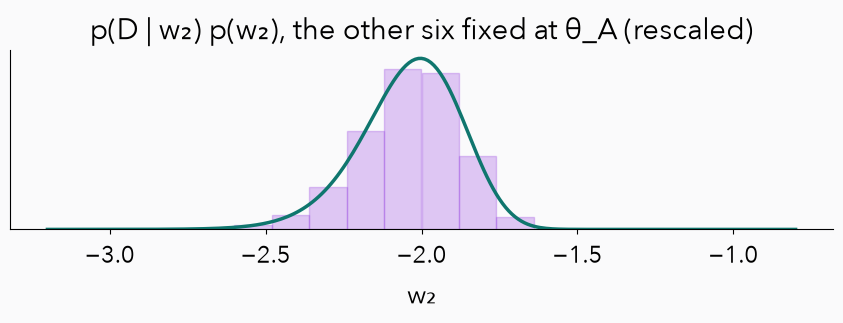

In [4]:
# One unknown: w2 varies, the other six parameters stay at θ_A. The integrand is p(D | w2) p(w2).
def log_integrand_w2(w2):
    theta = theta_A.repeat(len(w2), 1)
    theta[:, 1] = w2
    return bnn_log_lik(theta) + dist.Normal(0., 1.).log_prob(w2)
def log_riemann(lo, hi, n):
    width = (hi - lo) / n
    centres = lo + (torch.arange(n) + .5) * width
    return number(torch.logsumexp(log_integrand_w2(centres), 0) + math.log(width))
coarse = log_riemann(-3.2, -0.8, 20)        # the twenty rectangles on the slide
fine = log_riemann(-6.0, 4.0, 200_000)      # a much finer grid over a wider range
print(f"log of the area, 20 rectangles: {coarse:.4f}; 200,000 rectangles: {fine:.4f}")
assert abs(coarse - fine) < 5e-3
fixtures["story"]["bnn"]["evidence_1d"] = dict(lo=-3.2, hi=-.8, rectangles=20, log_area=coarse, log_area_fine=fine)
w = torch.linspace(-3.2, -.8, 241)
g = log_integrand_w2(w)
fig, ax = plt.subplots(figsize=(8.8, 3.6))
ax.plot(w, (g - g.max()).exp(), color=C["p"])
centres = -3.2 + (torch.arange(20) + .5) * .12
ax.bar(centres, (log_integrand_w2(centres) - g.max()).exp(), width=.12, color=C["q"], alpha=.25, edgecolor=C["q"])
ax.set(xlabel="w₂", yticks=[], title="p(D | w₂) p(w₂), the other six fixed at θ_A (rescaled)")
savefig("bnn-evidence-1d")

Sampling from the prior and averaging the likelihood does not rescue the seven-parameter integral either: almost every prior draw explains the data terribly, so the estimate is carried by a handful of lucky draws (optional slide [sampling from the prior](https://nipunbatra.github.io/generative/lectures/lecture1/#evidence-mc/1)).

1000 [-1092.95, -121.1, -23.37, -9.43, -2.57, -1.44, -1.4] · effective draws 77 · largest share 0.079
1001 [-879.09, -215.97, -16.38, -4.39, -0.68, -1.72, -1.41] · effective draws 93 · largest share 0.043
1002 [-1211.04, -44.28, -26.01, -6.24, -2.37, -1.59, -1.53] · effective draws 134 · largest share 0.035
1003 [-487.5, -100.7, -12.13, -2.54, -2.88, -1.2, -1.38] · effective draws 108 · largest share 0.035
log p(D) ≈ -1.43, the mean of the four 10-million-draw estimates


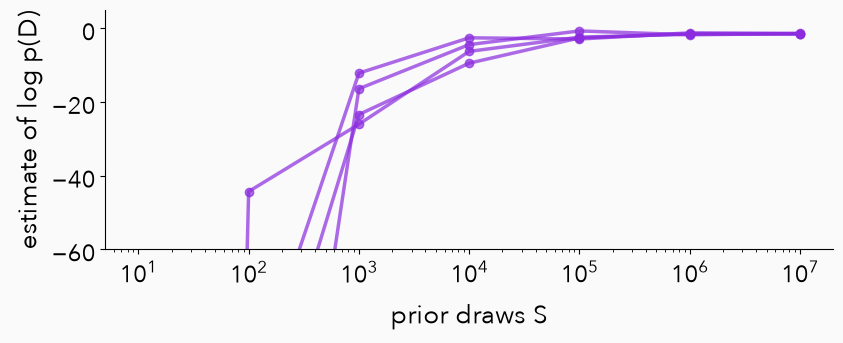

In [5]:
mc_sizes = [10, 100, 1_000, 10_000, 100_000, 1_000_000, 10_000_000]
evidence_runs = []
for seed in range(4):
    torch.manual_seed(1000 + seed)
    ll = torch.cat([bnn_log_lik(theta_prior.sample((500_000,))) for _ in range(20)])
    weights = torch.exp(ll - ll.max())
    evidence_runs.append(dict(seed=1000 + seed,
        estimates=[number(torch.logsumexp(ll[:S], 0)) - math.log(S) for S in mc_sizes],
        effective_draws=number(weights.sum() ** 2 / (weights ** 2).sum()),
        largest_share=number(weights.max() / weights.sum())))
log_evidence_bnn = float(np.mean([r["estimates"][-1] for r in evidence_runs]))
fixtures["story"]["bnn"]["evidence"] = dict(sizes=mc_sizes, runs=evidence_runs, estimate=log_evidence_bnn,
    grid_points_per_parameter=100, parameters=7)
for r in evidence_runs:
    print(r["seed"], [round(v, 2) for v in r["estimates"]], "· effective draws",
          round(r["effective_draws"]), "· largest share", round(r["largest_share"], 3))
print(f"log p(D) ≈ {log_evidence_bnn:.2f}, the mean of the four 10-million-draw estimates")
fig, ax = plt.subplots(figsize=(8.8, 3.8))
for r in evidence_runs:
    ax.plot(mc_sizes, r["estimates"], marker="o", color=C["q"], alpha=.7)
ax.set(xscale="log", ylim=(-60, 5), xlabel="prior draws S", ylabel="estimate of log p(D)")
savefig("bnn-evidence-mc")

### 1.5 Approximating the posterior: why, and three ways

Slides: [1.5 Predictions with error bars](https://nipunbatra.github.io/generative/lectures/lecture1/#predictive/1) · [the core problem](https://nipunbatra.github.io/generative/lectures/lecture1/#core-problem/1) · [three ways](https://nipunbatra.github.io/generative/lectures/lecture1/#three-ways/1) · [the VI idea](https://nipunbatra.github.io/generative/lectures/lecture1/#vi-idea/1)

What we want in the end is the **posterior predictive**, every network’s prediction averaged with posterior weights:
$$p(y^*\mid x^*,\mathcal D)=\int p(y^*\mid x^*,\theta)\,p(\theta\mid\mathcal D)\,d\theta.$$
A long Hamiltonian Monte Carlo run gives a reference here: four chains, `theta_A` as the start. The band should widen beyond the data and in the gap.

acceptance [0.904, 0.904, 0.89, 0.903]
predictive sd at x = −2.5, 0, 2.5: [0.215, 0.162, 0.168]


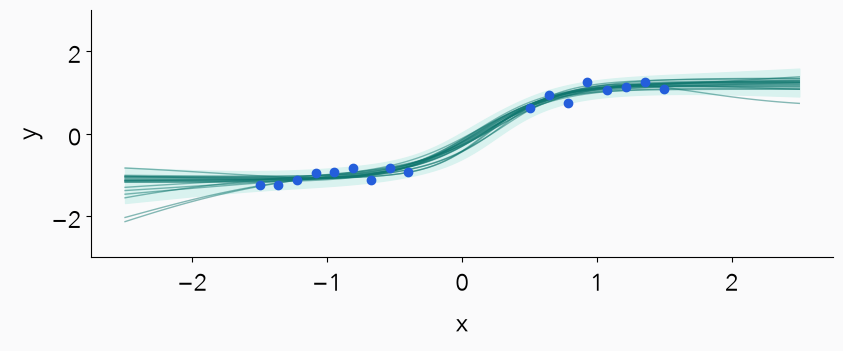

In [6]:
def hmc_chain(theta0, n_keep, n_warm, step_size, leapfrog, seed):
    torch.manual_seed(seed)
    def potential(t):
        t = t.clone().requires_grad_(True)
        U = -bnn_log_joint(t)
        grad, = torch.autograd.grad(U, t)
        return U.detach(), grad
    th, (U, grad) = theta0.clone(), potential(theta0)
    kept, accepted = [], 0
    for it in range(n_warm + n_keep):
        p0 = torch.randn(7)
        p_mom, t_new = p0 - .5 * step_size * grad, th.clone()
        for l in range(leapfrog):
            t_new = t_new + step_size * p_mom
            U_new, grad_new = potential(t_new)
            if l < leapfrog - 1:
                p_mom = p_mom - step_size * grad_new
        p_mom = p_mom - .5 * step_size * grad_new
        if torch.log(torch.rand(())) < (U + .5 * (p0 ** 2).sum()) - (U_new + .5 * (p_mom ** 2).sum()):
            th, U, grad = t_new, U_new, grad_new
            accepted += it >= n_warm
        if it >= n_warm:
            kept.append(th.clone())
    return torch.stack(kept), accepted / n_keep
chains = [hmc_chain(theta_A, 2000, 500, .02, 25, seed) for seed in (1, 2, 3, 4)]
hmc_samples = torch.cat([chain for chain, _ in chains])
F_post = net(hmc_samples, x_grid)
post_sd_f = F_post.std(0)
post_sd = (post_sd_f ** 2 + noise_sd ** 2).sqrt()
torch.manual_seed(13)
show = torch.randperm(len(hmc_samples))[:20]
fixtures["story"]["bnn"]["hmc"] = dict(chains=4, kept=2000, warmup=500, step_size=.02, leapfrog=25,
    acceptance=[rate for _, rate in chains], mean=F_post.mean(0).tolist(), sd_f=post_sd_f.tolist(),
    sd=post_sd.tolist(), draws=F_post[show].tolist())
print("acceptance", [round(rate, 3) for _, rate in chains])
print("predictive sd at x = −2.5, 0, 2.5:", [round(number(post_sd[i]), 3) for i in (0, 60, 120)])
fig, ax = plt.subplots(figsize=(8.8, 4))
m = F_post.mean(0)
ax.fill_between(x_grid, m - 2 * post_sd, m + 2 * post_sd, color="#D9F2EF")
for f_draw in F_post[show]:
    ax.plot(x_grid, f_draw, color=C["p"], lw=1, alpha=.5)
ax.scatter(x_train, y_train, color=C["data"], zorder=3)
ax.set(xlabel="x", ylabel="y", ylim=(-3, 3))
savefig("bnn-posterior-predictive")

#### Three ways around an intractable posterior

On a two-bump target, $0.7\,\mathcal N(-2,1)+0.3\,\mathcal N(2,1)$:

- **Laplace**: find the highest peak and fit a Gaussian to its curvature.
- **MCMC**: a random walk whose visits follow the target (random-walk Metropolis).
- **Variational inference**: the Gaussian $q$ closest to the target in $\mathrm{KL}(q\,\|\,p)$, found by gradient descent.

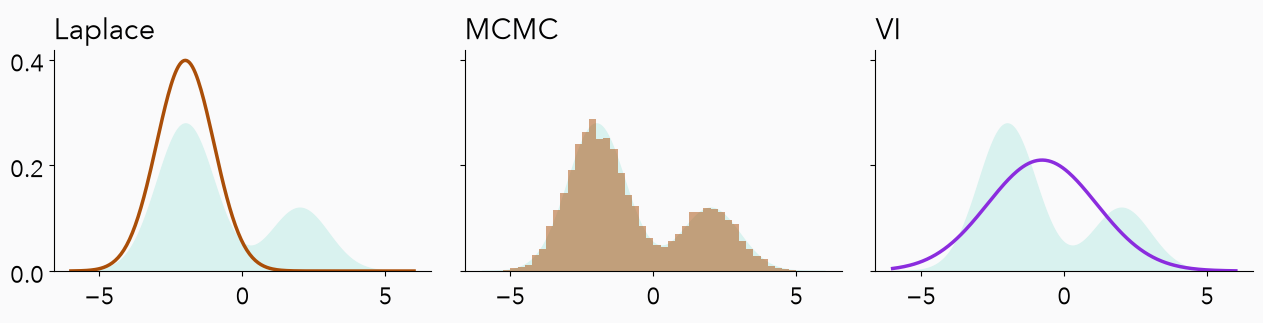

Laplace: [-1.9994236770045335, 1.001154476066346] · MCMC mean -0.801 acceptance 0.6069 · VI: [-0.775641838128022, 1.900747471367499]


In [7]:
three_target = dist.MixtureSameFamily(dist.Categorical(probs=torch.tensor([.7, .3])),
    dist.Normal(torch.tensor([-2., 2.]), torch.tensor([1., 1.])))
def grid_kl(a, b, grid):
    # KL(a || b) by the trapezoid rule on a fixed grid
    la, lb = a.log_prob(grid), b.log_prob(grid)
    return torch.trapezoid(la.exp() * (la - lb), grid)
# Laplace: the highest peak, then the curvature there
peak = torch.tensor(-1.0, requires_grad=True)
peak_opt = torch.optim.Adam([peak], lr=.05)
for _ in range(2000):
    loss = -three_target.log_prob(peak)
    peak_opt.zero_grad(); loss.backward(); peak_opt.step()
mode = peak.detach()
curvature = torch.autograd.functional.hessian(lambda t: three_target.log_prob(t), mode)
laplace = dist.Normal(mode, (-curvature).rsqrt())
# MCMC: random-walk Metropolis
torch.manual_seed(7)
state = torch.tensor(0.); state_lp = three_target.log_prob(state); chain = []; accepted = 0
for _ in range(20_000):
    proposal = state + 2.0 * torch.randn(())
    proposal_lp = three_target.log_prob(proposal)
    if torch.log(torch.rand(())) < proposal_lp - state_lp:
        state, state_lp, accepted = proposal, proposal_lp, accepted + 1
    chain.append(number(state))
chain = np.array(chain)
# VI: minimise KL(q || p) on a grid
grid3 = torch.linspace(-8, 8, 2001)
m3 = torch.nn.Parameter(torch.tensor(-.5)); rho3 = torch.nn.Parameter(torch.tensor(0.))
opt3 = torch.optim.Adam([m3, rho3], lr=.05)
for _ in range(600):
    loss = grid_kl(dist.Normal(m3, rho3.exp()), three_target, grid3)
    opt3.zero_grad(); loss.backward(); opt3.step()
vi3 = dist.Normal(m3.detach(), rho3.detach().exp())
x3 = torch.linspace(-6, 6, 241)
hist, edges = np.histogram(chain, bins=np.linspace(-6, 6, 49), density=True)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, title in zip(axes, ["Laplace", "MCMC", "VI"]):
    ax.fill_between(x3, 0, three_target.log_prob(x3).exp(), color="#D9F2EF")
    ax.set_title(title, loc="left")
axes[0].plot(x3, laplace.log_prob(x3).exp(), color=C["noise"])
axes[1].hist(chain, bins=edges, density=True, color=C["noise"], alpha=.5)
axes[2].plot(x3, vi3.log_prob(x3).exp(), color=C["q"])
savefig("three-ways")
fixtures["story"]["three"] = dict(weights=[.7, .3], means=[-2., 2.], scales=[1., 1.],
    laplace=[number(laplace.loc), number(laplace.scale)],
    mcmc=dict(steps=20_000, step_size=2.0, seed=7, acceptance=accepted / 20_000,
              mean=float(chain.mean()), hist=hist.tolist(), edges=edges.tolist()),
    vi=[number(vi3.loc), number(vi3.scale)], true_mean=.7 * -2 + .3 * 2,
    plot=dict(x=x3.tolist(), p=three_target.log_prob(x3).exp().tolist(),
              laplace=laplace.log_prob(x3).exp().tolist(), vi=vi3.log_prob(x3).exp().tolist()))
print("Laplace:", fixtures["story"]["three"]["laplace"], "· MCMC mean", round(float(chain.mean()), 3),
      "acceptance", accepted / 20_000, "· VI:", fixtures["story"]["three"]["vi"])

## Part 2 · How far apart are two distributions?

Slides: [Part 2](https://nipunbatra.github.io/generative/lectures/lecture1/#pretend-posterior/1). For a while we **pretend we know the posterior**, so that every tool can be checked against the right answer. We need one number for how far apart two distributions are. We build it from information theory, following [Jia-Bin Huang, “Fantastic KL Divergence and How to (Actually) Compute It”](https://www.youtube.com/watch?v=tXE23653JrU): surprise, entropy, codes, cross-entropy and KL, and then the losses you already train with. A second, hands-on route, grades in two runs of a course, is in the appendix.

### 2.1 Surprise: the information in one outcome

Slides: [2.1 A 90% forecast](https://nipunbatra.github.io/generative/lectures/lecture1/#surprise-forecast/1) · [what should surprise be?](https://nipunbatra.github.io/generative/lectures/lecture1/#surprise-candidates/1) · [five days](https://nipunbatra.github.io/generative/lectures/lecture1/#surprise-five/1) · [the surprise curve](https://nipunbatra.github.io/generative/lectures/lecture1/#surprise-curve/1)

The forecast says sun with probability 0.9 and rain with 0.1. Rain would surprise us more. We want a number $I(x)$ for the surprise of an outcome with probability $p(x)$ that is

1. **zero for a certain outcome**: $I=0$ when $p=1$;
2. **larger for rarer outcomes**;
3. **additive for independent outcomes**: two days’ probabilities multiply, $p(x_1)\,p(x_2)$, and their surprises should add.

Only the logarithm turns products into sums, so $I(x)=\log\frac1{p(x)}$. With $\log_2$ the unit is the **bit**, the surprise of a fair yes/no answer; with the natural log it is the **nat**; 1 nat = 1.44 bits.

sunny: p = 0.9, surprise = 0.152 bits = 0.105 nats
rainy: p = 0.1, surprise = 3.322 bits = 2.303 nats
five sunny days: p = 0.5905, surprise 0.760 bits = 5 × 0.152
sun, sun, rain, sun, sun: p = 0.06561, surprise 3.930 bits = 4 × 0.152 + 3.322
1 − p      f(1) = 0.00   f(0.5) = 0.50   f(0.1) = 0.90   f(0.5 × 0.1) = 0.95 vs f(0.5) + f(0.1) = 1.40
1/p        f(1) = 1.00   f(0.5) = 2.00   f(0.1) = 10.00   f(0.5 × 0.1) = 20.00 vs f(0.5) + f(0.1) = 12.00
log₂(1/p)  f(1) = 0.00   f(0.5) = 1.00   f(0.1) = 3.32   f(0.5 × 0.1) = 4.32 vs f(0.5) + f(0.1) = 4.32


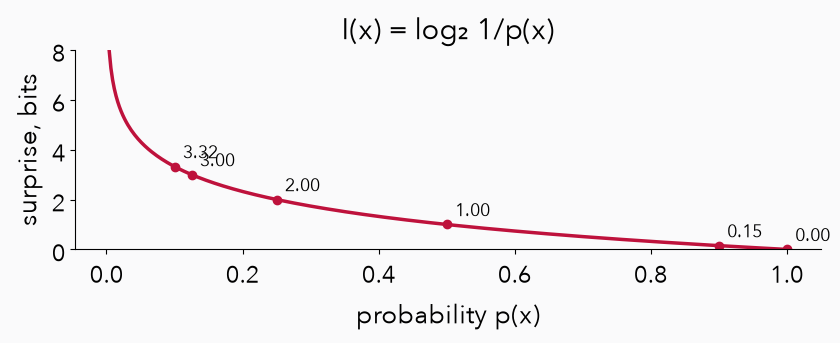

In [8]:
def surprise(p, base=2):
    "Self-information log(1/p): in bits for base 2, in nats for base e."
    return math.log(1 / p, base)
for name, pr in [("sunny", .9), ("rainy", .1)]:
    print(f"{name}: p = {pr}, surprise = {surprise(pr):.3f} bits = {surprise(pr, math.e):.3f} nats")
five_sun, one_rain = .9 ** 5, .9 ** 4 * .1
print(f"five sunny days: p = {five_sun:.4f}, surprise {surprise(five_sun):.3f} bits = 5 × {surprise(.9):.3f}")
print(f"sun, sun, rain, sun, sun: p = {one_rain:.5f}, surprise {surprise(one_rain):.3f} bits = 4 × {surprise(.9):.3f} + {surprise(.1):.3f}")
# Which function of p could measure surprise? Check the three requirements on three candidates.
candidates = {"1 − p": lambda x: 1 - x, "1/p": lambda x: 1 / x, "log₂(1/p)": surprise}
for name, fn in candidates.items():
    print(f"{name:10s} f(1) = {fn(1):.2f}   f(0.5) = {fn(.5):.2f}   f(0.1) = {fn(.1):.2f}   "
          f"f(0.5 × 0.1) = {fn(.05):.2f} vs f(0.5) + f(0.1) = {fn(.5) + fn(.1):.2f}")
fixtures["story"]["info"] = dict(forecast=[.9, .1], surprise_bits=[surprise(.9), surprise(.1)],
    five_sun=dict(p=five_sun, bits=surprise(five_sun)), one_rain=dict(p=one_rain, bits=surprise(one_rain)),
    candidates={name: [fn(1), fn(.5), fn(.1), fn(.05), fn(.5) + fn(.1)] for name, fn in candidates.items()})
pp = np.linspace(.004, 1, 400)
fig, ax = plt.subplots(figsize=(8.8, 3.8))
ax.plot(pp, np.log2(1 / pp), color=C["loss"])
for pr in [1, .5, .25, .125, .9, .1]:
    ax.plot(pr, surprise(pr), "o", color=C["loss"])
    ax.annotate(f"{surprise(pr):.2f}", (pr, surprise(pr)), xytext=(6, 6), textcoords="offset points", fontsize=13)
ax.set(xlabel="probability p(x)", ylabel="surprise, bits", ylim=(0, 8), title="I(x) = log₂ 1/p(x)")
savefig("surprise-curve")

### 2.2 Entropy: average surprise

Slides: [2.2 Average surprise](https://nipunbatra.github.io/generative/lectures/lecture1/#entropy-average/1) · [day after day](https://nipunbatra.github.io/generative/lectures/lecture1/#entropy-days/1) · [from 0 to 1 bit](https://nipunbatra.github.io/generative/lectures/lecture1/#entropy-explorer/1) · [three kinds of weather](https://nipunbatra.github.io/generative/lectures/lecture1/#entropy-three/1) · [yes/no questions](https://nipunbatra.github.io/generative/lectures/lecture1/#entropy-questions/1)

Entropy is the surprise we expect, on average, from one draw:
$$H(p)=\sum_x p(x)\log_2\frac1{p(x)}=\mathbb E_{x\sim p}\Big[\log_2\frac1{p(x)}\Big].$$
**Why an expectation?** Over many days, outcome $x$ happens on a fraction $p(x)$ of them, so the long-run average of the daily surprise is exactly this weighted sum. The cell checks it by simulating 10,000 days. A fair choice between two outcomes carries 1 bit; a certain outcome, 0.

p = [0.5, 0.5]: H = 1.0000 bits
p = [0.875, 0.125]: H = 0.5436 bits
p = [1.0, 0.0]: H = 0.0000 bits
p = [0.9, 0.1]: H = 0.4690 bits
p = [0.5, 0.25, 0.25]: H = 1.5000 bits
average surprise over     10 days: 0.1520 bits   (weighted sum H = 0.4690)
average surprise over    100 days: 0.3739 bits   (weighted sum H = 0.4690)
average surprise over  1,000 days: 0.4278 bits   (weighted sum H = 0.4690)
average surprise over 10,000 days: 0.4703 bits   (weighted sum H = 0.4690)


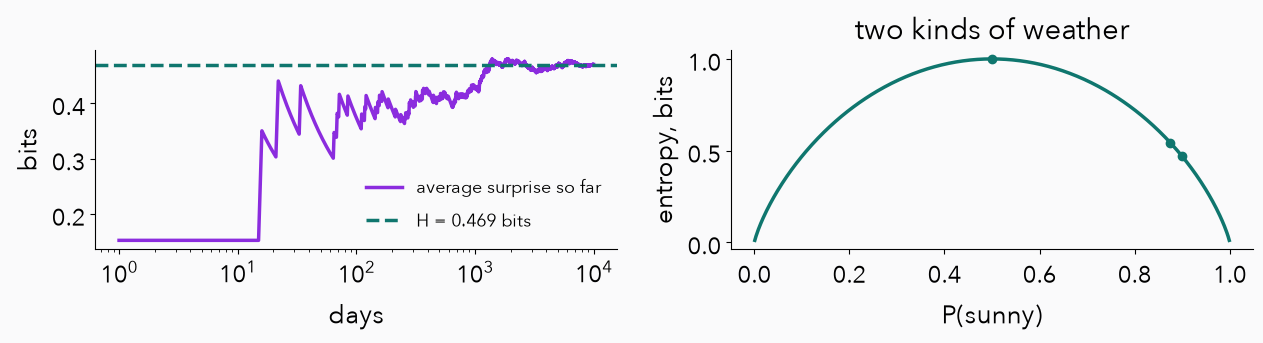

In [9]:
def entropy(probs, base=2):
    probs = np.asarray(probs, float); nz = probs > 0
    return float((probs[nz] * np.log(1 / probs[nz])).sum() / math.log(base))
for probs in ([.5, .5], [.875, .125], [1., 0.], [.9, .1], [.5, .25, .25]):
    print(f"p = {probs}: H = {entropy(probs):.4f} bits")
rng = np.random.default_rng(3)
days = rng.choice(2, size=10_000, p=[.9, .1])                    # 0 = sunny, 1 = rainy
daily = np.array([surprise(.9), surprise(.1)])[days]             # each day's surprise
running = np.cumsum(daily) / np.arange(1, len(days) + 1)
for S in [10, 100, 1_000, 10_000]:
    print(f"average surprise over {S:6,} days: {running[S - 1]:.4f} bits   (weighted sum H = {entropy([.9, .1]):.4f})")
fixtures["story"]["info"].update(entropy=dict(examples={"0.5": entropy([.5, .5]), "0.875": entropy([.875, .125]), "1.0": entropy([1., 0.])},
    forecast=entropy([.9, .1]), weather=entropy([.5, .25, .25]), days_seed=3,
    days_running=[float(running[S - 1]) for S in [10, 100, 1000, 10000]]))
qq = np.linspace(.001, .999, 400)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].semilogx(np.arange(1, len(days) + 1), running, color=C["q"], label="average surprise so far")
axes[0].axhline(entropy([.9, .1]), color=C["p"], ls="--", label="H = 0.469 bits")
axes[0].set(xlabel="days", ylabel="bits"); axes[0].legend(frameon=False, fontsize=13)
axes[1].plot(qq, [entropy([x, 1 - x]) for x in qq], color=C["p"])
for x in (.5, .875, .9):
    axes[1].plot(x, entropy([x, 1 - x]), "o", color=C["p"])
axes[1].set(xlabel="P(sunny)", ylabel="entropy, bits", title="two kinds of weather")
savefig("entropy")

### 2.3 Codes: entropy is the shortest average message

Slides: [2.3 Send the weather in bits](https://nipunbatra.github.io/generative/lectures/lecture1/#channel/1) · [prefix codes](https://nipunbatra.github.io/generative/lectures/lecture1/#prefix-code/1) · [Huffman’s recipe](https://nipunbatra.github.io/generative/lectures/lecture1/#huffman/1) · [code length = surprise](https://nipunbatra.github.io/generative/lectures/lecture1/#efficient-code/1)

Send each day’s weather as bits. A **prefix code** (no codeword is the start of another) can be read without separators. **Huffman’s algorithm** builds the best one: repeatedly merge the two least likely outcomes. For sunny ½, cloudy ¼, rainy ¼ it gives 0, 10, 11: **each codeword is exactly as long as its surprise**, so the average length is the entropy, 1.5 bits. No code can average fewer than $H(p)$ bits (Shannon, 1948).

In [10]:
import heapq, itertools
def huffman(probs):
    "Huffman's algorithm: repeatedly merge the two least likely nodes; the first popped gets 0, the second 1."
    order = itertools.count()
    heap = [(pr, next(order), {name: ""}) for name, pr in probs.items()]
    heapq.heapify(heap)
    while len(heap) > 1:
        p0, _, zero = heapq.heappop(heap)
        p1, _, one = heapq.heappop(heap)
        merged = {**{k: "0" + v for k, v in zero.items()}, **{k: "1" + v for k, v in one.items()}}
        heapq.heappush(heap, (p0 + p1, next(order), merged))
    return heap[0][2]
weather_names = ["sunny", "cloudy", "rainy"]
weather_p = np.array([.5, .25, .25])       # our town
weather_q = np.array([.25, .25, .5])       # a wrong belief: rain is the common one
code_p = huffman(dict(zip(weather_names, weather_p)))
code_q = huffman(dict(zip(weather_names, weather_q)))
def avg_len(code, probs):
    return float(sum(pr * len(code[n]) for n, pr in zip(weather_names, probs)))
for n, pr in zip(weather_names, weather_p):
    print(f"{n:7s} p = {pr:.2f}  surprise {surprise(pr):.0f} bits  code for p: {code_p[n]:3s}  code for q: {code_q[n]}")
print(f"average length on our weather: code for p {avg_len(code_p, weather_p)} bits = H(p) = {entropy(weather_p)}; code for q {avg_len(code_q, weather_p)} bits")
assert avg_len(code_p, weather_p) == entropy(weather_p) == 1.5
# Send 1,000 days through both codes and count the bits actually sent.
rng = np.random.default_rng(7)
sent = rng.choice(3, size=1_000, p=weather_p)
stream_p = "".join(code_p[weather_names[k]] for k in sent)
stream_q = "".join(code_q[weather_names[k]] for k in sent)
print("first ten days:", [weather_names[k] for k in sent[:10]])
print("  code for p:", stream_p[:20], "…   code for q:", stream_q[:20], "…")
print(f"bits per day over 1,000 days: code for p {len(stream_p) / 1000:.3f}, code for q {len(stream_q) / 1000:.3f}, "
      f"difference {(len(stream_q) - len(stream_p)) / 1000:.3f}")
entropy_bits = entropy(weather_p)
cross_entropy_bits = float(-(weather_p * np.log2(weather_q)).sum())
fixtures["story"]["bits"] = dict(p=weather_p.tolist(), q=weather_q.tolist(), entropy=entropy_bits, cross_entropy=cross_entropy_bits,
    kl=cross_entropy_bits - entropy_bits, names=weather_names, right_code=[code_p[n] for n in weather_names],
    wrong_code=[code_q[n] for n in weather_names], uniform_code=["00", "01", "10"], uniform_length=2.,
    simulation=dict(seed=7, days=1000, bits_p=len(stream_p), bits_q=len(stream_q)))

sunny   p = 0.50  surprise 1 bits  code for p: 0    code for q: 10
cloudy  p = 0.25  surprise 2 bits  code for p: 10   code for q: 11
rainy   p = 0.25  surprise 2 bits  code for p: 11   code for q: 0
average length on our weather: code for p 1.5 bits = H(p) = 1.5; code for q 1.75 bits
first ten days: ['cloudy', 'rainy', 'rainy', 'sunny', 'sunny', 'rainy', 'sunny', 'rainy', 'rainy', 'sunny']
  code for p: 10111100110111100000 …   code for q: 11001010010001010101 …
bits per day over 1,000 days: code for p 1.498, code for q 1.747, difference 0.249


### 2.4 Cross-entropy and KL: the cost of a wrong belief

Slides: [2.4 A wrong belief](https://nipunbatra.github.io/generative/lectures/lecture1/#wrong-belief/1) · [cross-entropy](https://nipunbatra.github.io/generative/lectures/lecture1/#cross-entropy/1) · [1,000 days through both codes](https://nipunbatra.github.io/generative/lectures/lecture1/#bits-days/1) · [the extra bits](https://nipunbatra.github.io/generative/lectures/lecture1/#kl-extra-bits/1) · [asymmetry](https://nipunbatra.github.io/generative/lectures/lecture1/#kl-asymmetry/1)

A station designed for $q$ gives outcome $x$ about $\log_2\frac1{q(x)}$ bits. On our weather $p$ its average is the **cross-entropy** $H(p,q)=\sum_x p(x)\log_2\frac1{q(x)}$. The extra bits over the best code are the **KL divergence**:
$$\mathrm{KL}(p\|q)=H(p,q)-H(p)=\sum_x p(x)\log_2\frac{p(x)}{q(x)}\ \ge0 .$$
It is not symmetric: which distribution is the truth matters.

In [11]:
def kl_bits(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float); nz = a > 0
    return float((a[nz] * np.log2(a[nz] / b[nz])).sum())
print(f"H(p) = {entropy(weather_p)} bits, H(p, q) = {cross_entropy_bits} bits, KL(p‖q) = {kl_bits(weather_p, weather_q)} bits")
assert abs(cross_entropy_bits - entropy(weather_p) - kl_bits(weather_p, weather_q)) < 1e-12
terms = weather_p * np.log2(weather_p / weather_q)
print("per-outcome terms p·log₂(p/q):", dict(zip(weather_names, terms.round(3))), "→ sum", terms.sum())
library_bits = number(dist.kl_divergence(dist.Categorical(probs=torch.tensor(weather_p)),
                                         dist.Categorical(probs=torch.tensor(weather_q)))) / math.log(2)
assert abs(library_bits - kl_bits(weather_p, weather_q)) < 1e-12
# Asymmetry: a town where it is almost always sunny
sunny_town = np.array([.98, .01, .01])
fwd, rev = kl_bits(weather_p, sunny_town), kl_bits(sunny_town, weather_p)
print(f"our weather, their code: KL(p‖q) = {fwd:.3f} bits;  their weather, our code: KL(q‖p) = {rev:.3f} bits")
fixtures["story"]["info"].update(kl=dict(terms=terms.tolist(), library_bits=library_bits,
    asym=dict(q=sunny_town.tolist(), fwd=fwd, rev=rev, codeword_bits=[surprise(x) for x in sunny_town])))

H(p) = 1.5 bits, H(p, q) = 1.75 bits, KL(p‖q) = 0.25 bits
per-outcome terms p·log₂(p/q): {'sunny': np.float64(0.5), 'cloudy': np.float64(0.0), 'rainy': np.float64(-0.25)} → sum 0.25
our weather, their code: KL(p‖q) = 1.837 bits;  their weather, our code: KL(q‖p) = 0.859 bits


### 2.5 Classification: the loss is the surprise at the true label

Slides: [2.5 A classifier outputs a distribution](https://nipunbatra.github.io/generative/lectures/lecture1/#classifier/1) · [the loss is a surprise](https://nipunbatra.github.io/generative/lectures/lecture1/#ce-surprise/1) · [cross-entropy is KL](https://nipunbatra.github.io/generative/lectures/lecture1/#ce-is-kl/1) · [soft labels](https://nipunbatra.github.io/generative/lectures/lecture1/#soft-labels/1)

A classifier outputs $q=(0.05,0.05,0.60,0.30)$ over ape, bear, cat and dog for a cat image. The label is a distribution too, one-hot $p=(0,0,1,0)$, with entropy 0. So the cross-entropy is $-\log q(\text{cat})$: **the model’s surprise at the true label**, and it equals $\mathrm{KL}(p\|q)$. PyTorch’s `F.cross_entropy` uses the natural log (nats). With soft labels, such as a teacher’s predictions in knowledge distillation, cross-entropy = $H(p)$ + KL, and $H(p)$ does not depend on the model.

In [12]:
import torch.nn.functional as F
classes = ["ape", "bear", "cat", "dog"]
q_pred = torch.tensor([.05, .05, .60, .30])          # the classifier's softmax output
target = torch.tensor([2])                            # the label: cat
logits = q_pred.log()[None]                           # any logits with this softmax give the same loss
loss = number(F.cross_entropy(logits, target))
print(f"F.cross_entropy = {loss:.4f} nats = {loss / math.log(2):.4f} bits;  −log q(cat) = {-math.log(.6):.4f} nats")
assert abs(loss + math.log(.6)) < 1e-12
kl_onehot = number((1. * (1. / q_pred[2])).log())
print(f"KL(one-hot ‖ q) = {kl_onehot:.4f} nats: the same number, because a one-hot label has entropy 0")
teacher = torch.tensor([.02, .03, .75, .20])          # a teacher's soft label (knowledge distillation)
ce_soft = number(-(teacher * q_pred.log()).sum())
h_soft = number(-(teacher * teacher.log()).sum())
kl_soft = number((teacher * (teacher / q_pred).log()).sum())
print(f"soft label: cross-entropy {ce_soft:.4f} = entropy {h_soft:.4f} + KL {kl_soft:.4f} nats")
assert abs(ce_soft - h_soft - kl_soft) < 1e-12
assert abs(number(F.cross_entropy(logits, teacher[None])) - ce_soft) < 1e-12
fixtures["story"]["classify"] = dict(classes=classes, pred=q_pred.tolist(), label=2, loss_nats=loss, loss_bits=loss / math.log(2),
    kl_onehot=kl_onehot, teacher=teacher.tolist(), ce_soft=ce_soft, entropy_soft=h_soft, kl_soft=kl_soft,
    curve={str(x): -math.log(x) for x in (1., .9, .6, .3, .05, .01)})

F.cross_entropy = 0.5108 nats = 0.7370 bits;  −log q(cat) = 0.5108 nats
KL(one-hot ‖ q) = 0.5108 nats: the same number, because a one-hot label has entropy 0
soft label: cross-entropy 0.7737 = entropy 0.7211 + KL 0.0526 nats


### 2.6 Maximum likelihood is minimum KL: twenty days of data

Slides: [2.6 The data](https://nipunbatra.github.io/generative/lectures/lecture1/#mle-data/1) · [their likelihood](https://nipunbatra.github.io/generative/lectures/lecture1/#mle-likelihood/1) · [average surprise](https://nipunbatra.github.io/generative/lectures/lecture1/#mle-surprise/1) · [group the days](https://nipunbatra.github.io/generative/lectures/lecture1/#mle-group/1) · [find the best q](https://nipunbatra.github.io/generative/lectures/lecture1/#mle-fit/1) · [the general statement](https://nipunbatra.github.io/generative/lectures/lecture1/#mle-kl/1)

Twenty recorded days: 10 sunny, 5 cloudy, 5 rainy. A model $q$ gives these data the probability $\prod_i q(x_i)$. Per day, minus its log is the data’s average surprise under $q$. Grouping the days by weather turns it into a cross-entropy with the data’s own frequencies $\hat p$:
$$-\frac1N\sum_{i=1}^{N}\log_2 q(x_i)=\sum_x\hat p(x)\log_2\frac1{q(x)}=H(\hat p,q)=H(\hat p)+\mathrm{KL}(\hat p\,\|\,q).$$
$H(\hat p)$ is fixed by the data, so **maximising the likelihood minimises $\mathrm{KL}(\hat p\|q)$**, and the best $q$ is $\hat p$, the frequencies. The second cell finds it by gradient descent on the average surprise, without being told.

In [13]:
rng = np.random.default_rng(2026)
data = rng.permutation([0] * 10 + [1] * 5 + [2] * 5)            # 0 = sunny, 1 = cloudy, 2 = rainy
counts = np.bincount(data, minlength=3)
p_hat = counts / len(data)
print("the data:", " ".join(["☀", "⛅", "🌧"][k] for k in data))
print("counts:", dict(zip(weather_names, counts.tolist())), "→ frequencies p̂ =", p_hat)
def avg_surprise(q):
    return float(np.mean(np.log2(1 / np.asarray(q, float)[data])))
for name, q in [("q = (¼, ¼, ½)", weather_q), ("q = p̂ = (½, ¼, ¼)", p_hat)]:
    log_lik = float(np.log2(np.asarray(q)[data]).sum())
    print(f"{name}: log₂ p(D | q) = {log_lik:.1f} bits, p(D | q) = {2 ** log_lik:.3g}; average surprise {avg_surprise(q):.3f} bits"
          f" = H(p̂) {entropy(p_hat):.3f} + KL {kl_bits(p_hat, q):.3f}")
    assert abs(avg_surprise(q) - entropy(p_hat) - kl_bits(p_hat, q)) < 1e-12
ratio = 2 ** (len(data) * (avg_surprise(weather_q) - avg_surprise(p_hat)))
print(f"the data are {ratio:.0f} times more probable under p̂ than under q = (¼, ¼, ½)")
fixtures["story"]["mle"] = dict(seed=2026, data=data.tolist(), counts=counts.tolist(), p_hat=p_hat.tolist(), q=weather_q.tolist(),
    log_lik_q=float(np.log2(weather_q[data]).sum()), log_lik_hat=float(np.log2(p_hat[data]).sum()),
    avg_q=avg_surprise(weather_q), avg_hat=avg_surprise(p_hat), ratio=ratio)

the data: ⛅ 🌧 ☀ ☀ ⛅ ☀ ☀ 🌧 ☀ ⛅ ⛅ ☀ 🌧 🌧 ☀ ☀ 🌧 ☀ ☀ ⛅
counts: {'sunny': 10, 'cloudy': 5, 'rainy': 5} → frequencies p̂ = [0.5  0.25 0.25]
q = (¼, ¼, ½): log₂ p(D | q) = -35.0 bits, p(D | q) = 2.91e-11; average surprise 1.750 bits = H(p̂) 1.500 + KL 0.250
q = p̂ = (½, ¼, ¼): log₂ p(D | q) = -30.0 bits, p(D | q) = 9.31e-10; average surprise 1.500 bits = H(p̂) 1.500 + KL 0.000
the data are 32 times more probable under p̂ than under q = (¼, ¼, ½)


In [14]:
# Maximum likelihood by gradient descent: three logits, a softmax, and the data's average surprise as the loss.
logits_w = torch.nn.Parameter(torch.zeros(3))
opt_w = torch.optim.Adam([logits_w], lr=.05)
data_t = torch.tensor(data)
for step in range(2000):
    nll = -torch.log_softmax(logits_w, 0)[data_t].mean()
    opt_w.zero_grad(); nll.backward(); opt_w.step()
fitted = torch.softmax(logits_w.detach(), 0)
print("gradient descent finds q =", fitted.numpy().round(4), "· the frequencies were", p_hat)
assert torch.allclose(fitted, torch.tensor(p_hat), atol=1e-3)
fixtures["story"]["mle"]["fitted"] = fitted.tolist()

gradient descent finds q = [0.5  0.25 0.25] · the frequencies were [0.5  0.25 0.25]


### 2.7 KL at work: distillation and RLHF

Slides: [2.7 The same quantity in many losses](https://nipunbatra.github.io/generative/lectures/lecture1/#kl-everywhere/1) · [a big teacher, a small student](https://nipunbatra.github.io/generative/lectures/lecture1/#distill-why/1) · [the distillation loss](https://nipunbatra.github.io/generative/lectures/lecture1/#distill-loss/1) · [a real student](https://nipunbatra.github.io/generative/lectures/lecture1/#distill-demo/1) · [RLHF](https://nipunbatra.github.io/generative/lectures/lecture1/#rlhf-setup/1) · [the KL leash](https://nipunbatra.github.io/generative/lectures/lecture1/#rlhf-beta/1)

**Knowledge distillation** ([Hinton, Vinyals and Dean, 2015](https://arxiv.org/abs/1503.02531)): a big, accurate *teacher* is too slow to deploy, so a small *student* learns to reproduce the teacher’s output distribution. The loss is $\mathrm{KL}(p_{\text{teacher}}\,\|\,q_{\text{student}})$ on the same inputs, with the teacher frozen. The teacher’s soft labels say more than a one-hot label: which wrong classes are plausible.

**RLHF**: a language model, the *policy* $\pi$, is fine-tuned to maximise a learned reward, minus $\beta\,\mathrm{KL}(\pi\,\|\,\pi_{\text{ref}})$ to a frozen copy of where it started. Without that leash it drifts to whatever fools the reward model. Over a small set of replies the best policy has a closed form, $\pi^*(y)\propto\pi_{\text{ref}}(y)\,e^{r(y)/\beta}$, which the second cell checks by gradient ascent.

teacher: 4,547 parameters, test accuracy 0.846
student: 27 parameters, test accuracy 0.850, agrees with the teacher on 97.0% of test points
KL(teacher ‖ student) on test points: 1.067 nats at the start, 0.0090 after 3,000 steps


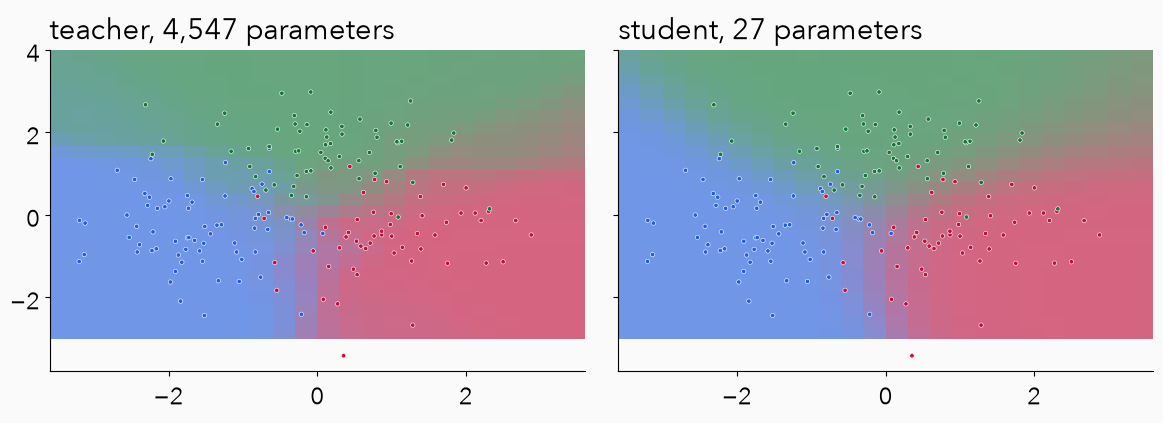

In [15]:
# Knowledge distillation on a toy problem: three overlapping classes in the plane.
centres = torch.tensor([[-1.3, -.4], [1.3, -.4], [0., 1.5]])
def sample_points(n, seed):
    g = torch.Generator().manual_seed(seed)
    y = torch.randint(0, 3, (n,), generator=g)
    return centres[y] + .9 * torch.randn(n, 2, generator=g), y
x_tr, y_tr = sample_points(3000, 1)
x_te, y_te = sample_points(4000, 2)
def mlp(sizes, seed):
    torch.manual_seed(seed)
    layers = []
    for a, b in zip(sizes[:-1], sizes[1:]):
        layers += [torch.nn.Linear(a, b), torch.nn.Tanh()]
    return torch.nn.Sequential(*layers[:-1])
def n_params(model):
    return sum(w.numel() for w in model.parameters())
teacher_net = mlp([2, 64, 64, 3], seed=10)                     # the big teacher, trained on labels
opt_t = torch.optim.Adam(teacher_net.parameters(), lr=.01)
for step in range(400):                                        # short training: a big net overfits noisy labels
    loss_t = F.cross_entropy(teacher_net(x_tr), y_tr)
    opt_t.zero_grad(); loss_t.backward(); opt_t.step()
with torch.no_grad():
    p_teacher_tr = torch.softmax(teacher_net(x_tr), -1)       # soft labels on the training inputs
    p_teacher_te = torch.softmax(teacher_net(x_te), -1)
def kl_rows(target, logits):
    "KL(target ‖ softmax(logits)) for each row, in nats"
    return (target * (target.clamp_min(1e-12).log() - torch.log_softmax(logits, -1))).sum(-1)
student_net = mlp([2, 4, 3], seed=11)                         # the small student
opt_s = torch.optim.Adam(student_net.parameters(), lr=.03)
gx, gy = torch.meshgrid(torch.linspace(-3.6, 3.6, 24), torch.linspace(-3, 4, 24), indexing="xy")
grid_pts = torch.stack([gx.flatten(), gy.flatten()], -1)
record, frames, kl_curve = [0, 25, 50, 100, 200, 400, 800, 1600, 3000], [], []
for step in range(3001):
    with torch.no_grad():
        kl_now = number(kl_rows(p_teacher_te, student_net(x_te)).mean())
        if step % 50 == 0:
            kl_curve.append([step, kl_now])
        if step in record:
            frames.append([step, kl_now, torch.softmax(student_net(grid_pts), -1).round(decimals=3).tolist()])
    if step == 3000:
        break
    loss_s = kl_rows(p_teacher_tr, student_net(x_tr)).mean()     # the distillation loss: only the student learns
    opt_s.zero_grad(); loss_s.backward(); opt_s.step()
with torch.no_grad():
    teacher_acc = number((teacher_net(x_te).argmax(-1) == y_te).double().mean())
    student_acc = number((student_net(x_te).argmax(-1) == y_te).double().mean())
    agree = number((student_net(x_te).argmax(-1) == teacher_net(x_te).argmax(-1)).double().mean())
    teacher_grid = torch.softmax(teacher_net(grid_pts), -1).round(decimals=3).tolist()
print(f"teacher: {n_params(teacher_net):,} parameters, test accuracy {teacher_acc:.3f}")
print(f"student: {n_params(student_net):,} parameters, test accuracy {student_acc:.3f}, agrees with the teacher on {agree:.1%} of test points")
print(f"KL(teacher ‖ student) on test points: {frames[0][1]:.3f} nats at the start, {frames[-1][1]:.4f} after 3,000 steps")
assert frames[-1][1] < .1 * frames[0][1]
fixtures["story"]["distill"] = dict(teacher_params=n_params(teacher_net), student_params=n_params(student_net),
    teacher_acc=teacher_acc, student_acc=student_acc, agree=agree, kl_curve=kl_curve, frames=frames, teacher_grid=teacher_grid,
    grid=dict(x=[-3.6, 3.6], y=[-3., 4.], n=24), points=x_tr[:180].tolist(), labels=y_tr[:180].tolist(), centres=centres.tolist())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
cols = np.array([[.14, .37, .86], [.75, .07, .24], [.08, .47, .22]])
for ax, probs, title in [(axes[0], teacher_grid, f"teacher, {n_params(teacher_net):,} parameters"), (axes[1], frames[-1][2], f"student, {n_params(student_net)} parameters")]:
    img = (np.array(probs) @ cols).reshape(24, 24, 3)
    ax.imshow(.35 + .65 * img, origin="lower", extent=[-3.6, 3.6, -3, 4], aspect="auto")
    ax.scatter(*x_tr[:180].T, c=cols[y_tr[:180]], s=10, edgecolors="white", linewidths=.4)
    ax.set_title(title, loc="left")
savefig("distillation")

In [16]:
# RLHF in miniature: five possible replies to one prompt, a frozen reference model and a reward model.
replies = ["Yes, it is hot. Careful!", "Yes.", "It might be.", "No.", "YES!!! AMAZING STOVE!!!"]
pi_ref = torch.tensor([.40, .30, .20, .09, .01])             # the pretrained model's probabilities
reward = torch.tensor([1.0, .6, .3, -1.0, 2.0])               # a reward model that is fooled by enthusiasm
def best_policy(beta):
    "argmax over π of E_π[r] − β KL(π ‖ π_ref): π*(y) ∝ π_ref(y) exp(r(y)/β)"
    w = pi_ref * torch.exp(reward / beta)
    return w / w.sum()
def kl_ref(pi_):
    return number((pi_ * (pi_ / pi_ref).log()).sum())
policies = {}
for beta in [.05, .1, .2, .5, 1., 2., 5., 20.]:
    pb = best_policy(beta)
    policies[str(beta)] = dict(probs=pb.tolist(), reward=number((pb * reward).sum()), kl=kl_ref(pb))
    print(f"β = {beta:5}: π* = {pb.numpy().round(3)}, expected reward {number((pb * reward).sum()):.3f}, KL(π*‖π_ref) = {kl_ref(pb):.3f}")
# The closed form, checked by gradient ascent on the objective at β = 1
logits_r = torch.nn.Parameter(pi_ref.log().clone())
opt_r = torch.optim.Adam([logits_r], lr=.05)
for step in range(3000):
    pi_ = torch.softmax(logits_r, 0)
    loss_r = -((pi_ * reward).sum() - 1. * (pi_ * (torch.log_softmax(logits_r, 0) - pi_ref.log())).sum())
    opt_r.zero_grad(); loss_r.backward(); opt_r.step()
assert torch.allclose(torch.softmax(logits_r.detach(), 0), best_policy(1.), atol=1e-4)
print("gradient ascent at β = 1 lands on the closed form:", torch.softmax(logits_r.detach(), 0).numpy().round(4))
fixtures["story"]["rlhf"] = dict(replies=replies, ref=pi_ref.tolist(), reward=reward.tolist(), policies=policies,
    ref_reward=number((pi_ref * reward).sum()), gd_check=torch.softmax(logits_r.detach(), 0).tolist())

β =  0.05: π* = [0. 0. 0. 0. 1.], expected reward 2.000, KL(π*‖π_ref) = 4.605
β =   0.1: π* = [0.002 0.    0.    0.    0.998], expected reward 1.998, KL(π*‖π_ref) = 4.585
β =   0.2: π* = [0.207 0.021 0.003 0.    0.769], expected reward 1.758, KL(π*‖π_ref) = 3.132
β =   0.5: π* = [0.606 0.204 0.075 0.002 0.112], expected reward 0.973, KL(π*‖π_ref) = 0.362
β =   1.0: π* = [0.541 0.272 0.134 0.016 0.037], expected reward 0.801, KL(π*‖π_ref) = 0.103
β =   2.0: π* = [0.478 0.294 0.169 0.04  0.02 ], expected reward 0.705, KL(π*‖π_ref) = 0.031
β =   5.0: π* = [0.433 0.3   0.188 0.065 0.013], expected reward 0.631, KL(π*‖π_ref) = 0.006
β =  20.0: π* = [0.409 0.3   0.197 0.083 0.011], expected reward 0.586, KL(π*‖π_ref) = 0.000


gradient ascent at β = 1 lands on the closed form: [0.5407 0.2718 0.1343 0.0165 0.0367]


### 2.8 Closed forms, and what PyTorch computes

Slides: [2.8 From sums to integrals](https://nipunbatra.github.io/generative/lectures/lecture1/#densities/1) · [Bernoulli](https://nipunbatra.github.io/generative/lectures/lecture1/#bern-pmf/1) · [categorical](https://nipunbatra.github.io/generative/lectures/lecture1/#cat-pmf/1) · [Gaussian](https://nipunbatra.github.io/generative/lectures/lecture1/#gauss-pdf/1) · [diagonal Gaussian](https://nipunbatra.github.io/generative/lectures/lecture1/#diag-pdf/1) · [PyTorch’s source](https://nipunbatra.github.io/generative/lectures/lecture1/#torch-discrete/1)

For continuous $\theta$ the sum becomes an integral, $\mathrm{KL}(p\|q)=\int p(\theta)\log\frac{p(\theta)}{q(\theta)}\,d\theta$. For four families the average has a formula:

| $p$ and $q$ | $\mathrm{KL}(p\,\|\,q)$ |
|---|---|
| Bernoulli$(a)$, Bernoulli$(b)$ | $a\log\frac ab+(1-a)\log\frac{1-a}{1-b}$ |
| Categorical$(\pi)$, Categorical$(\rho)$ | $\sum_k\pi_k\log\frac{\pi_k}{\rho_k}$ |
| $\mathcal N(\mu,\sigma^2)$, $\mathcal N(m,s^2)$ | $\log\frac s\sigma+\frac{\sigma^2+(\mu-m)^2}{2s^2}-\frac12$ |
| diagonal Gaussians | the sum of the one-dimensional KLs |

The next cell checks each formula against `torch.distributions.kl_divergence` and prints PyTorch’s own implementation ([source on GitHub](https://github.com/pytorch/pytorch/blob/main/torch/distributions/kl.py)).

In [17]:
import inspect
from torch.distributions import kl as torch_kl
def row(name, by_hand, library):
    print(f"{name:34s} by hand {by_hand:.6f}   PyTorch {library:.6f}")
    assert abs(by_hand - library) < 1e-12
    return dict(by_hand=by_hand, torch=library)
closed = {}
a, b = .8, .5        # Bernoulli(0.8) against Bernoulli(0.5)
closed["bernoulli"] = dict(a=a, b=b, **row("Bernoulli(0.8) ‖ Bernoulli(0.5)",
    a * math.log(a / b) + (1 - a) * math.log((1 - a) / (1 - b)),
    number(dist.kl_divergence(dist.Bernoulli(torch.tensor(a)), dist.Bernoulli(torch.tensor(b))))))
pi, rho_c = torch.tensor([.4, .1, .5]), torch.tensor([.1, .4, .5])   # this year's and last year's grades
closed["categorical"] = dict(pi=pi.tolist(), rho=rho_c.tolist(), **row("Categorical: the grades",
    number((pi * (pi / rho_c).log()).sum()),
    number(dist.kl_divergence(dist.Categorical(probs=pi), dist.Categorical(probs=rho_c)))))
mu, sigma, m, s = 0., 2., 1., 4.     # q = N(0, 2²) against p = N(1, 4²)
closed["normal"] = dict(mu=mu, sigma=sigma, m=m, s=s, **row("N(0, 2²) ‖ N(1, 4²)",
    math.log(s / sigma) + (sigma ** 2 + (mu - m) ** 2) / (2 * s ** 2) - .5,
    number(dist.kl_divergence(dist.Normal(mu, sigma), dist.Normal(m, s)))))
mu7 = torch.tensor([.6, -.8, .2, -.3, .9, -.5, .1]); sd7 = torch.tensor([.5, .35, .6, .3, .45, .4, .25])
q7 = dist.Independent(dist.Normal(mu7, sd7), 1)            # one bell per parameter, as in our network
prior7 = dist.Independent(dist.Normal(torch.zeros(7), torch.ones(7)), 1)
closed["diagonal"] = dict(mu=mu7.tolist(), sigma=sd7.tolist(), **row("diagonal q against N(0, I), d = 7",
    number((-sd7.log() + (sd7 ** 2 + mu7 ** 2) / 2 - .5).sum()),
    number(dist.kl_divergence(q7, prior7))))
fixtures["story"]["closed_forms"] = closed
print()
print(inspect.getsource(torch_kl._kl_normal_normal))
print(inspect.getsource(torch_kl._kl_independent_independent))

Bernoulli(0.8) ‖ Bernoulli(0.5)    by hand 0.192745   PyTorch 0.192745
Categorical: the grades            by hand 0.415888   PyTorch 0.415888
N(0, 2²) ‖ N(1, 4²)                by hand 0.349397   PyTorch 0.349397
diagonal q against N(0, I), d = 7  by hand 4.782611   PyTorch 4.782611

@register_kl(Normal, Normal)
def _kl_normal_normal(p, q):
    var_ratio = (p.scale / q.scale).pow(2)
    t1 = ((p.loc - q.loc) / q.scale).pow(2)
    return 0.5 * (var_ratio + t1 - 1 - var_ratio.log())

@register_kl(Independent, Independent)
def _kl_independent_independent(p, q):
    if p.reinterpreted_batch_ndims != q.reinterpreted_batch_ndims:
        raise NotImplementedError
    result = kl_divergence(p.base_dist, q.base_dist)
    return _sum_rightmost(result, p.reinterpreted_batch_ndims)



#### Use the formula: which Gaussian is closer?

Slides: [the PML vote](https://nipunbatra.github.io/generative/lectures/lecture1/#compare-formula/1)

Fix $p=\mathcal N(1,4^2)$. Compare $q_1=\mathcal N(0,2^2)$ and $q_2=\mathcal N(1,3^2)$.

**Predict first:** compare their centres and widths. A visual judgement motivates a score; it does not define one.

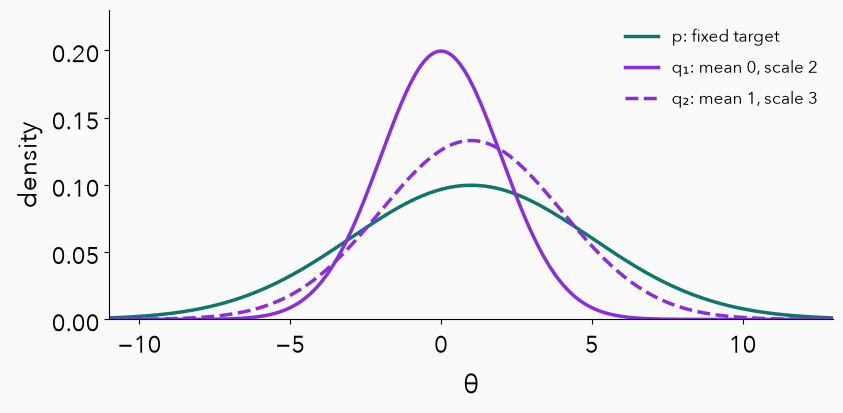

In [18]:
p = dist.Normal(torch.tensor(1.), torch.tensor(4.))
q1 = dist.Normal(torch.tensor(0.), torch.tensor(2.))
q2 = dist.Normal(torch.tensor(1.), torch.tensor(3.))
theta_grid = torch.linspace(-11, 13, 481)
fig, ax = plt.subplots(figsize=(8.8, 4.5))
for d, label, col, style in [(p, "p: fixed target", C["p"], "-"),
                            (q1, "q₁: mean 0, scale 2", C["q"], "-"),
                            (q2, "q₂: mean 1, scale 3", C["q"], "--")]:
    ax.plot(theta_grid, d.log_prob(theta_grid).exp(), label=label, color=col, ls=style)
ax.set(xlim=(-11,13), ylim=(0,.23), xlabel="θ", ylabel="density")
ax.legend(frameon=False, fontsize=12)
savefig("gaussian-candidates")

#### A local log ratio, then an average

Slides: [KL is an area you can watch](https://nipunbatra.github.io/generative/lectures/lecture1/#kl-area/1)

$\log q(\theta)-\log p(\theta)$ compares the two densities at one place. The first argument in

$$\mathrm{KL}(q\|p)=\mathbb E_{\theta\sim q}\left[\log q(\theta)-\log p(\theta)\right]$$

says which distribution weights the average. A local log ratio can be negative; the weighted average, the KL, cannot. For two Normals, the formula from 2.4 needs one moment: $\mathbb E_q[(\theta-m)^2]=\sigma^2+(\mu-m)^2$, because the cross term vanishes, $\mathbb E_q[\theta-\mu]=0$. The cell checks the formula against PyTorch and against a direct numerical integral.

In [19]:
normal_values = {}
for name, q in [("q1", q1), ("q2", q2)]:
    manual = normal_kl(q,p)
    library = dist.kl_divergence(q,p)
    reverse = dist.kl_divergence(p,q)
    assert torch.allclose(manual, library, atol=1e-12, rtol=0)
    check_grid=torch.linspace(number(q.loc-12*q.scale),number(q.loc+12*q.scale),100001)
    integral=torch.trapezoid(q.log_prob(check_grid).exp()*
                            (q.log_prob(check_grid)-p.log_prob(check_grid)),check_grid)
    assert abs(number(manual-integral))<1e-9
    normal_values[name] = dict(mu=number(q.loc), sigma=number(q.scale),
                             kl=number(manual), reverse_kl=number(reverse),quadrature=number(integral))
    print(f"{name}: KL(q||p) = {manual:.9f}; KL(p||q) = {reverse:.9f} nats")
assert dist.kl_divergence(p,p) == 0
print("Matched distributions: KL(p||p) =", number(dist.kl_divergence(p,p)))
fixtures["normal"] = {"target": {"mu":1., "sigma":4.}, "candidates":normal_values}

q1: KL(q||p) = 0.349397181; KL(p||q) = 0.931852819 nats
q2: KL(q||p) = 0.068932072; KL(p||q) = 0.101206816 nats
Matched distributions: KL(p||p) = 0.0


### 2.9 KL by sampling

Slides: [2.9 KL is an average](https://nipunbatra.github.io/generative/lectures/lecture1/#kl-expectation/1) · [two ways to compute an expectation](https://nipunbatra.github.io/generative/lectures/lecture1/#expectation-sampling/1) · [sample the weather](https://nipunbatra.github.io/generative/lectures/lecture1/#mc-weather/1) · [the code](https://nipunbatra.github.io/generative/lectures/lecture1/#kl-sampling/1) · [watch it settle](https://nipunbatra.github.io/generative/lectures/lecture1/#mc-live/1)

KL is an **expectation**: $\mathrm{KL}(p\|q)=\mathbb E_{x\sim p}\big[\log\frac{p(x)}{q(x)}\big]$. An expectation can be computed three ways: a weighted sum $\sum_x p(x)f(x)$, an integral $\int p(\theta)f(\theta)\,d\theta$, or a **sample average** $\frac1S\sum_s f(x_s)$ with $x_s\sim p$. Draws land on each value in proportion to its probability, so the plain average weights each $f(x)$ by $p(x)$ by itself. First with the weather of 2.4, where the exact answer is 0.25 bits.

S =     10 days: average log₂(p/q) = 0.4000 bits  (exact KL 0.2500)
S =    100 days: average log₂(p/q) = 0.3600 bits  (exact KL 0.2500)
S =  1,000 days: average log₂(p/q) = 0.2950 bits  (exact KL 0.2500)
S = 10,000 days: average log₂(p/q) = 0.2676 bits  (exact KL 0.2500)


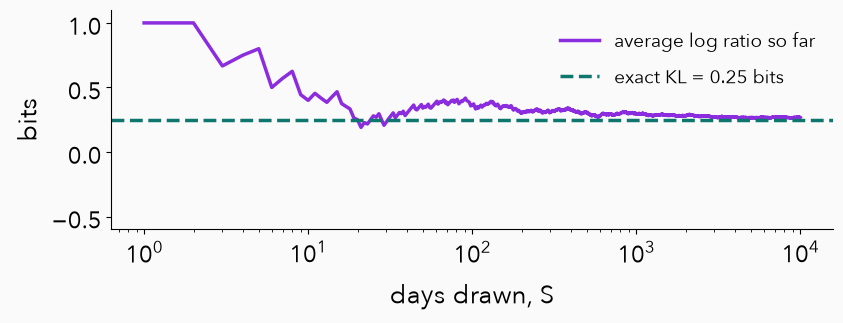

In [20]:
rng = np.random.default_rng(11)
days8 = rng.choice(3, size=10_000, p=weather_p)                  # days drawn from our weather p
log_ratio = np.log2(weather_p / weather_q)                        # +1, 0 and −1 bits
running = np.cumsum(log_ratio[days8]) / np.arange(1, len(days8) + 1)
for S in [10, 100, 1_000, 10_000]:
    print(f"S = {S:6,} days: average log₂(p/q) = {running[S - 1]:.4f} bits  (exact KL {kl_bits(weather_p, weather_q):.4f})")
fixtures["story"]["weather_sampling"] = dict(seed=11, sizes=[10, 100, 1000, 10000],
    estimates=[float(running[S - 1]) for S in [10, 100, 1000, 10000]])
fig, ax = plt.subplots(figsize=(8.8, 3.6))
ax.semilogx(np.arange(1, len(days8) + 1), running, color=C["q"], label="average log ratio so far")
ax.axhline(kl_bits(weather_p, weather_q), color=C["p"], ls="--", label="exact KL = 0.25 bits")
ax.set(xlabel="days drawn, S", ylabel="bits", ylim=(-.6, 1.1)); ax.legend(frameon=False, fontsize=14)
savefig("weather-sampling")

#### The code on the slide, run

Slides: [no formula needed: estimate KL by sampling](https://nipunbatra.github.io/generative/lectures/lecture1/#kl-sampling/1)

Now a continuous pair with a known answer, $q_2=\mathcal N(1,3^2)$ against $p=\mathcal N(1,4^2)$. Draw $\theta_1,\dots,\theta_S$ from **q**, score each draw with both log densities, and average:

$$\widehat{\mathrm{KL}}_S=\frac1S\sum_{s=1}^S\big[\log q(\theta_s)-\log p(\theta_s)\big].$$

estimate from 10,000 draws: 0.0671;  exact: 0.0689


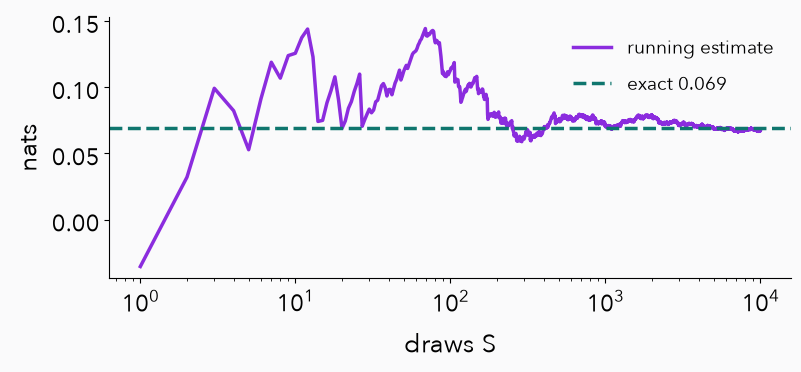

In [21]:
q, S = q2, 10_000
torch.manual_seed(1000)
theta = q.sample((S,))
log_q = q.log_prob(theta)
log_p = p.log_prob(theta)
est = (log_q - log_p).mean()
exact = dist.kl_divergence(q, p)
print(f"estimate from {S:,} draws: {est:.4f};  exact: {exact:.4f}")
running = (log_q - log_p).cumsum(0) / torch.arange(1, S + 1)
fig, ax = plt.subplots(figsize=(8.8, 3.4))
ax.semilogx(torch.arange(1, S + 1), running, color=C["q"], label="running estimate")
ax.axhline(number(exact), color=C["p"], ls="--", label=f"exact {number(exact):.3f}")
ax.set(xlabel="draws S", ylabel="nats"); ax.legend(frameon=False, fontsize=14)
plt.show()

In [22]:
def mc_kl(q,p,samples,seed):
    torch.manual_seed(seed)
    draws=q.sample((samples,))
    terms=q.log_prob(draws)-p.log_prob(draws)
    return terms.mean(), terms.std(unbiased=True)/math.sqrt(samples)

# The same estimator as a function, reused below: a seed for each call makes every estimate reproducible.
print("mc_kl(q2, p, 10_000, seed=1000) =", round(number(mc_kl(q2, p, 10_000, 1000)[0]), 4))

mc_kl(q2, p, 10_000, seed=1000) = 0.0671


#### Live demo · more draws, tighter estimates

Slides: [watch the estimate settle](https://nipunbatra.github.io/generative/lectures/lecture1/#mc-live/1) · optional: [more samples, tighter estimates](https://nipunbatra.github.io/generative/lectures/lecture1/#mc-variability/1)

Keep p and q₂ fixed. Vary only the number of draws and the seed. The exact KL is unchanged. Larger S reduces estimator variance; individual estimates need not move monotonically towards the answer.

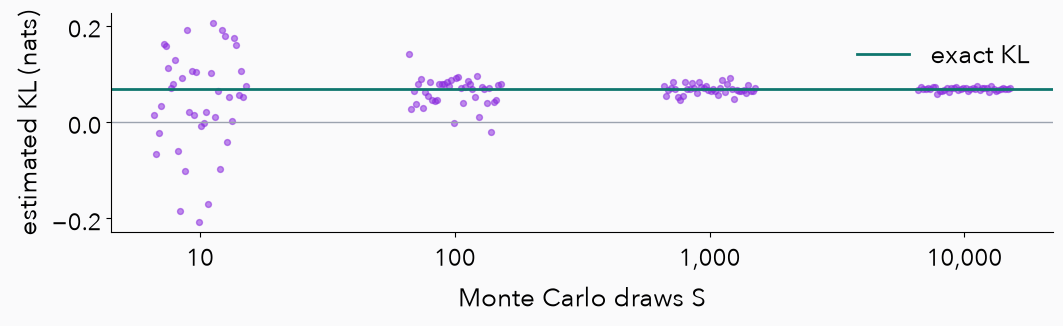

[(10, 0.10428), (100, 0.02956), (1000, 0.01022), (10000, 0.00335)]


In [23]:
repeats=[]
for size in [10,100,1000,10000]:
    vals=[number(mc_kl(q2,p,size,1000+j)[0]) for j in range(40)]
    repeats.append(dict(samples=size,seeds=list(range(1000,1040)),estimates=vals,
                        empirical_mean=float(np.mean(vals)),empirical_std=float(np.std(vals,ddof=1))))
fig,ax=plt.subplots(figsize=(11,3.6))
for i,row in enumerate(repeats):
    jitter=np.linspace(-.18,.18,len(row["estimates"]))
    ax.scatter(i+jitter,row["estimates"],s=18,color=C["q"],alpha=.55)
ax.axhline(number(dist.kl_divergence(q2,p)),color=C["p"],label="exact KL",lw=2)
ax.axhline(0,color="#9CA3AF",lw=1)
ax.set(xticks=range(4),xticklabels=["10","100","1,000","10,000"],
       xlabel="Monte Carlo draws S",ylabel="estimated KL (nats)")
ax.legend(frameon=False,fontsize=19)
savefig("mc-variability")
fixtures["monte_carlo"]={"q":"q2","exact_kl":number(dist.kl_divergence(q2,p)),
                         "repeats":repeats}
print([(r["samples"],round(r["empirical_std"],5)) for r in repeats])

Optional slide: [five draws can give a negative estimate](https://nipunbatra.github.io/generative/lectures/lecture1/#optional-negative-estimate/1). A finite-sample KL estimate can be negative even though the true KL is nonnegative. The next cell deliberately finds the first seed giving a negative **five-draw estimate**, as a counterexample. This seed selection is not a performance comparison.

In [24]:
negative_seed=next(s for s in range(1000) if number(mc_kl(q2,p,5,s)[0])<0)
torch.manual_seed(negative_seed)
draws=q2.sample((5,))
terms=q2.log_prob(draws)-p.log_prob(draws)
fixtures["monte_carlo"]["negative_example"]=dict(seed=negative_seed,samples=5,
    selection="first seed in 0..999 giving a negative estimate; intentional counterexample",
    draws=draws.tolist(),log_q=q2.log_prob(draws).tolist(),log_p=p.log_prob(draws).tolist(),
    terms=terms.tolist(),estimate=number(terms.mean()))
print("Selected seed:",negative_seed)
for x,lq,lp,t in zip(draws,q2.log_prob(draws),p.log_prob(draws),terms):
    print(f"θ={x: .4f}  log q={lq: .4f}  log p={lp: .4f}  difference={t: .4f}")
print("Five-draw estimate:",number(terms.mean()),"· exact KL:",number(dist.kl_divergence(q2,p)))

Selected seed: 0
θ= 5.6230  log q=-3.2049  log p=-2.9731  difference=-0.2318
θ= 0.1197  log q=-2.0606  log p=-2.3294  difference= 0.2688
θ=-5.5364  log q=-4.3911  log p=-3.6404  difference=-0.7508
θ= 2.7053  log q=-2.1791  log p=-2.3961  difference= 0.2170
θ=-2.2536  log q=-2.6056  log p=-2.6360  difference= 0.0304
Five-draw estimate: -0.09325773189856931 · exact KL: 0.0689320724517809


## Part 3 · Find the closest q

Slides: [Part 3](https://nipunbatra.github.io/generative/lectures/lecture1/#six-candidates/1). We can score any $q$ against $p$. Now find the best one: search a grid, then walk downhill with gradients, in one and two dimensions; then a target with no formula, where we must sample, and the trick that lets gradients through the samples.

### 3.1 Search a grid

Slides: [3.1 Six candidates](https://nipunbatra.github.io/generative/lectures/lecture1/#six-candidates/1) · [search a grid (hover it)](https://nipunbatra.github.io/generative/lectures/lecture1/#grid-search/1)

Every $(\mu,\sigma)$ is one candidate $q=\mathcal N(\mu,\sigma^2)$ with a score $\mathrm{KL}(q\|p)$ against the fixed $p=\mathcal N(1,4^2)$. A grid tries them all. It finds the answer here, but its cost explodes with the number of parameters.

q = N( 0, 2²): KL(q‖p) = 0.3494
q = N( 1, 3²): KL(q‖p) = 0.0689
q = N( 4, 1²): KL(q‖p) = 1.1988
q = N(-3, 4²): KL(q‖p) = 0.5000
q = N( 1, 8²): KL(q‖p) = 0.8069
q = N( 2, 5²): KL(q‖p) = 0.0894
2,040 evaluations; best grid point N(1.00, 4.00²), KL 0.00000
the network's q has 14 numbers: a grid with 40 values each needs 40**14 = 2.68e+22 evaluations


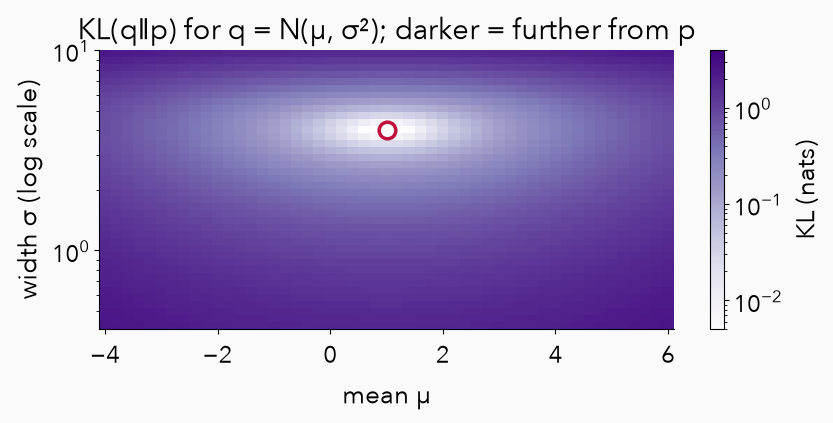

In [25]:
candidates = [(0, 2), (1, 3), (4, 1), (-3, 4), (1, 8), (2, 5)]
for mu_c, sd_c in candidates:
    print(f"q = N({mu_c:2d}, {sd_c}²): KL(q‖p) = {number(dist.kl_divergence(dist.Normal(float(mu_c), float(sd_c)), p)):.4f}")
# A 51 × 40 grid: means from −4.1 to 6.1, widths on a log scale from about 0.6 to 15
mus = -4.1 + (torch.arange(51) + .5) * (10.2 / 51)
dl = math.log(25) / 40
log_sds = math.log(4) - 28.5 * dl + (torch.arange(40) + .5) * dl
M, LS = torch.meshgrid(mus, log_sds, indexing="ij")
K = dist.kl_divergence(dist.Normal(M, LS.exp()), p)
i, j = divmod(int(K.argmin()), 40)
best_grid = dict(mu=number(mus[i]), sigma=number(log_sds[j].exp()), kl=number(K[i, j]))
print(f"{K.numel():,} evaluations; best grid point N({best_grid['mu']:.2f}, {best_grid['sigma']:.2f}²), KL {best_grid['kl']:.5f}")
print(f"the network's q has 14 numbers: a grid with 40 values each needs 40**14 = {40 ** 14:.2e} evaluations")
fixtures["story"]["grid"] = dict(candidates=[[c[0], c[1], number(dist.kl_divergence(dist.Normal(float(c[0]), float(c[1])), p))] for c in candidates],
    nx=51, ny=40, best=best_grid)
fig, ax = plt.subplots(figsize=(8.8, 4.6))
im = ax.pcolormesh(mus, LS[0].exp(), K.T, cmap="Purples", norm=matplotlib.colors.LogNorm(vmin=.005, vmax=4), shading="nearest")
ax.set(yscale="log", xlabel="mean μ", ylabel="width σ (log scale)", title="KL(q‖p) for q = N(μ, σ²); darker = further from p")
ax.plot(best_grid["mu"], best_grid["sigma"], "o", mfc="none", mec=C["loss"], ms=12, mew=2.5)
fig.colorbar(im, ax=ax, label="KL (nats)")
savefig("kl-grid")

### 3.2 Gradient descent

Slides: [3.2 Walk downhill](https://nipunbatra.github.io/generative/lectures/lecture1/#walk-downhill/1) · [the same search in code](https://nipunbatra.github.io/generative/lectures/lecture1/#fit-code/1) · [press play](https://nipunbatra.github.io/generative/lectures/lecture1/#olive/1) · optional: [one literal update](https://nipunbatra.github.io/generative/lectures/lecture1/#optional-one-step/1)

Instead of evaluating everywhere, follow the gradient of the KL with respect to $q$’s parameters. **First, one literal step by hand.** Hold $\sigma=2$ fixed and start at $\mu=0$:

$$\frac{\partial L}{\partial\mu}=\frac{\mu-1}{16},\qquad
\mu^+=\mu-\eta\frac{\partial L}{\partial\mu}.$$

With the chosen $\eta=4$, predict the new mean before running the cell. A negative derivative means gradient descent moves the mean right.

In [26]:
mu = torch.tensor(0., requires_grad=True)
q = dist.Normal(mu, torch.tensor(2.))
before = dist.kl_divergence(q,p)
before.backward()
gradient = number(mu.grad)
eta = 4.
with torch.no_grad():
    mu_after = mu - eta*mu.grad
after = dist.kl_divergence(dist.Normal(mu_after, torch.tensor(2.)), p)
h = 1e-5
fd = (normal_kl(dist.Normal(mu.detach()+h,2.),p)
      - normal_kl(dist.Normal(mu.detach()-h,2.),p))/(2*h)
assert abs(gradient-number(fd)) < 1e-9
assert number(after) < number(before)
fixtures["normal"]["one_step"] = dict(mu_before=0., sigma=2., eta=eta,
    gradient=gradient, mu_after=number(mu_after), kl_before=number(before),
    kl_after=number(after), finite_difference=number(fd),
    fixed_scale_best_kl=number(dist.kl_divergence(dist.Normal(1.,2.),p)))
print(fixtures["normal"]["one_step"])

{'mu_before': 0.0, 'sigma': 2.0, 'eta': 4.0, 'gradient': -0.0625, 'mu_after': 0.25, 'kl_before': 0.3493971805599453, 'kl_after': 0.3357253055599453, 'finite_difference': -0.06250000000318501, 'fixed_scale_best_kl': 0.3181471805599453}


Moving only the mean cannot match a width of 4. Its best possible KL is still positive.

To learn both parameters, optimise unconstrained $\mu,\rho$ and construct $\sigma=\exp(\rho)>0$. Here $\rho$ means **log standard deviation**, not log variance. The following saved trajectory is an actual deterministic optimisation of analytic KL.

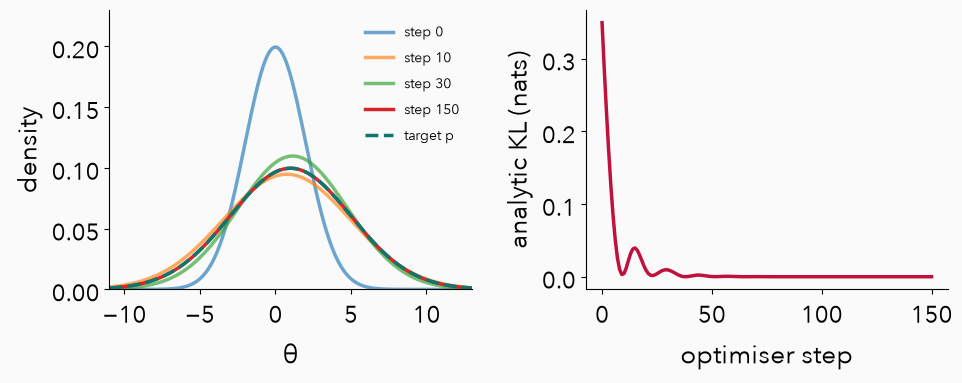

Final measured parameters: {'step': 150, 'mu': 0.9996269406912135, 'sigma': 3.999989449268585, 'kl': 4.356121350359381e-09}


In [27]:
mu = torch.nn.Parameter(torch.tensor(0.))
rho = torch.nn.Parameter(torch.tensor(math.log(2.)))
opt = torch.optim.Adam([mu, rho], lr=.08)
normal_trace = []
for step in range(151):
    q = dist.Normal(mu, rho.exp())
    loss = dist.kl_divergence(q,p)
    normal_trace.append(dict(step=step, mu=number(mu), sigma=number(rho.exp()), kl=number(loss)))
    if step == 150: break
    opt.zero_grad()
    loss.backward()
    opt.step()
assert normal_trace[-1]["kl"] < 1e-6
assert all(row["sigma"] > 0 for row in normal_trace)
fixtures["normal"]["training"] = dict(method="Adam on analytic KL", lr=.08, steps=150,
    parameterisation="sigma=exp(rho)", trace=normal_trace)
fig, axes = plt.subplots(1,2,figsize=(10,4.2))
for step in [0,10,30,150]:
    row = normal_trace[step]
    q = dist.Normal(row["mu"],row["sigma"])
    axes[0].plot(theta_grid,q.log_prob(theta_grid).exp(),label=f"step {step}",alpha=.65 if step<150 else 1)
axes[0].plot(theta_grid,p.log_prob(theta_grid).exp(),color=C["p"],ls="--",label="target p")
axes[0].set(xlim=(-11,13),ylim=(0,.23),xlabel="θ",ylabel="density")
axes[0].legend(fontsize=10,frameon=False)
axes[1].plot([r["step"] for r in normal_trace],[r["kl"] for r in normal_trace],color=C["loss"])
axes[1].set(xlabel="optimiser step",ylabel="analytic KL (nats)")
savefig("gaussian-fit")
print("Final measured parameters:", normal_trace[-1])

#### The code on the slide, run: from $\mathcal N(4,0.5^2)$ to $p$

Slides: [the same search in code](https://nipunbatra.github.io/generative/lectures/lecture1/#fit-code/1) · [press play](https://nipunbatra.github.io/generative/lectures/lecture1/#olive/1)

This is the slide’s loop, line for line, with imports so it runs on its own. It stores $\rho=\log\sigma$, so $\sigma=e^\rho$ stays positive whatever a step does. We record the loss, $\mu$ and $\sigma$ at every step: the raw optimisation, then the learned curve. The slide animation replays exactly these numbers.

step   0: μ =  4.000, σ =  0.500, loss = KL(q‖p) = 1.86850
step  25: μ =  2.797, σ =  1.726, loss = KL(q‖p) = 0.53465
step  50: μ =  1.852, σ =  4.347, loss = KL(q‖p) = 0.02999
step  75: μ =  1.292, σ =  3.925, loss = KL(q‖p) = 0.00301
step 100: μ =  1.057, σ =  4.020, loss = KL(q‖p) = 0.00012
step 125: μ =  0.997, σ =  3.991, loss = KL(q‖p) = 0.00001
step 150: μ =  0.995, σ =  4.004, loss = KL(q‖p) = 0.00000
step 175: μ =  0.999, σ =  3.999, loss = KL(q‖p) = 0.00000
step 200: μ =  1.000, σ =  4.000, loss = KL(q‖p) = 0.00000
step 200: μ =  1.000, σ =  4.000, loss = KL(q‖p) = 0.00000


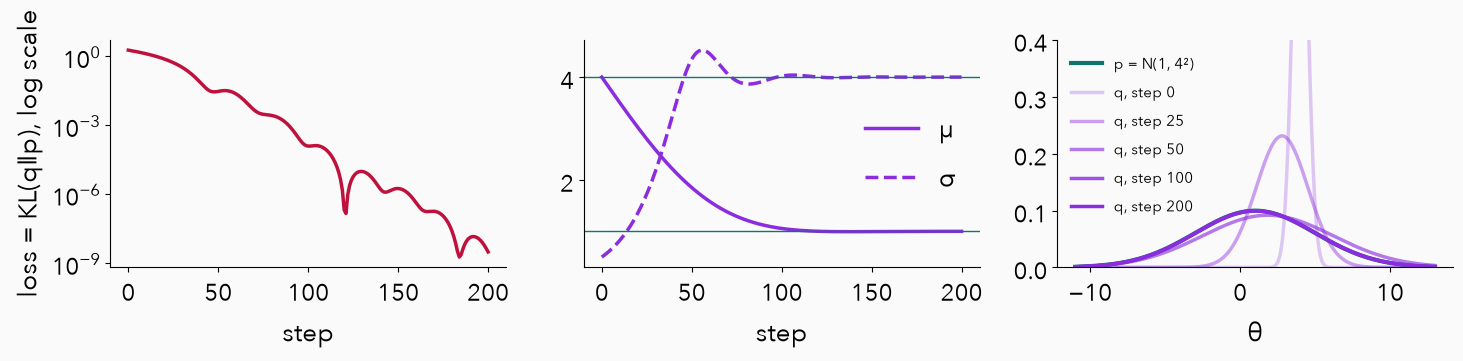

In [28]:
from math import log
from torch import tensor
from torch.nn import Parameter
from torch.optim import Adam
from torch.distributions import Normal, kl_divergence

p = Normal(tensor(1.0), tensor(4.0))        # the fixed target
mu  = Parameter(tensor(4.0))
rho = Parameter(tensor(log(0.5)))
opt = Adam([mu, rho], lr=0.05)
history = []                                # [step, μ, σ, loss] before each update
for step in range(200):
    q = Normal(mu, rho.exp())
    loss = kl_divergence(q, p)
    history.append([step, mu.item(), rho.exp().item(), loss.item()])
    opt.zero_grad()
    loss.backward()
    opt.step()
history.append([200, mu.item(), rho.exp().item(), kl_divergence(Normal(mu, rho.exp()), p).item()])
fixtures["story"]["olive"] = dict(start=[4., .5], lr=.05, steps=200, frames=history)
for step_, m_, s_, l_ in history[::25] + [history[-1]]:
    print(f"step {step_:3d}: μ = {m_:6.3f}, σ = {s_:6.3f}, loss = KL(q‖p) = {l_:.5f}")
H_ = np.array(history)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].semilogy(H_[:, 0], H_[:, 3], color=C["loss"]); axes[0].set(xlabel="step", ylabel="loss = KL(q‖p), log scale")
axes[1].plot(H_[:, 0], H_[:, 1], color=C["q"], label="μ"); axes[1].plot(H_[:, 0], H_[:, 2], color=C["q"], ls="--", label="σ")
axes[1].axhline(1, color=C["p"], lw=1); axes[1].axhline(4, color=C["p"], lw=1); axes[1].set(xlabel="step"); axes[1].legend(frameon=False)
axes[2].plot(theta_grid, p.log_prob(theta_grid).exp(), color=C["p"], lw=3, label="p = N(1, 4²)")
for k, step_ in enumerate([0, 25, 50, 100, 200]):
    _, m_, s_, _ = history[step_]
    axes[2].plot(theta_grid, Normal(m_, s_).log_prob(theta_grid).exp(), color=C["q"], alpha=.25 + .75 * k / 4, label=f"q, step {step_}")
axes[2].set(xlabel="θ", ylim=(0, .4)); axes[2].legend(frameon=False, fontsize=11)
savefig("gaussian-olive")

Scrub through the run yourself. The slider needs `ipywidgets`, which Colab and most Jupyter installations include; the slide has the same animation.

No ipywidgets here: showing steps 0, 50 and 200 instead.


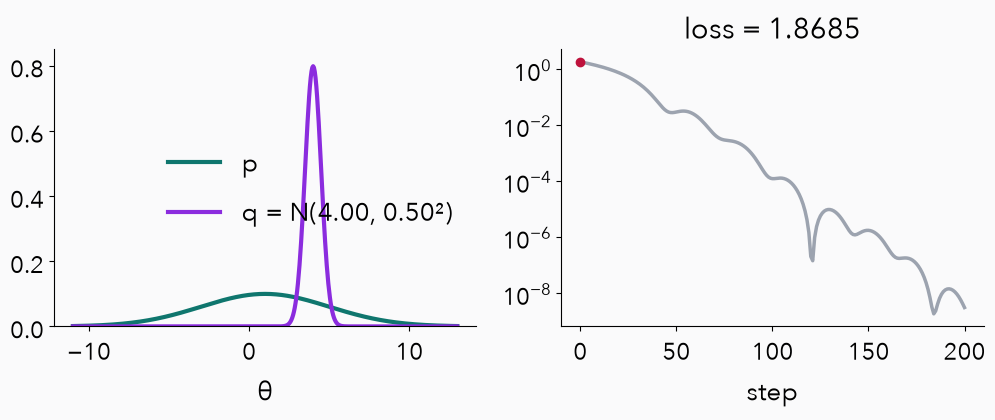

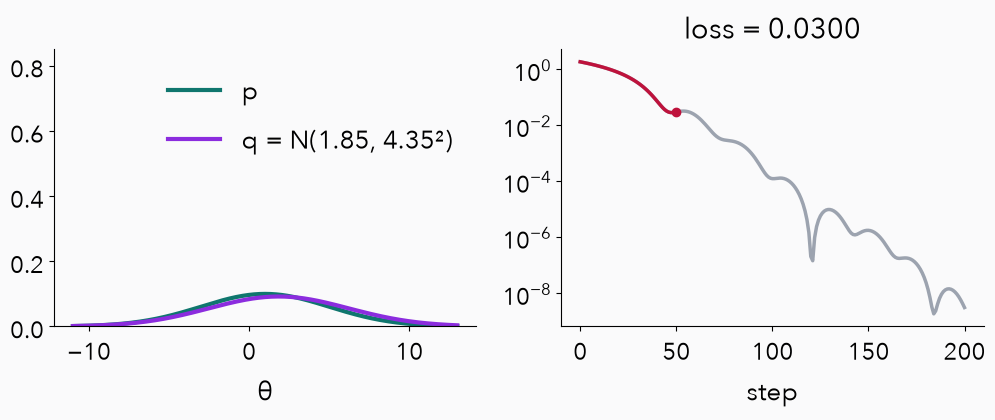

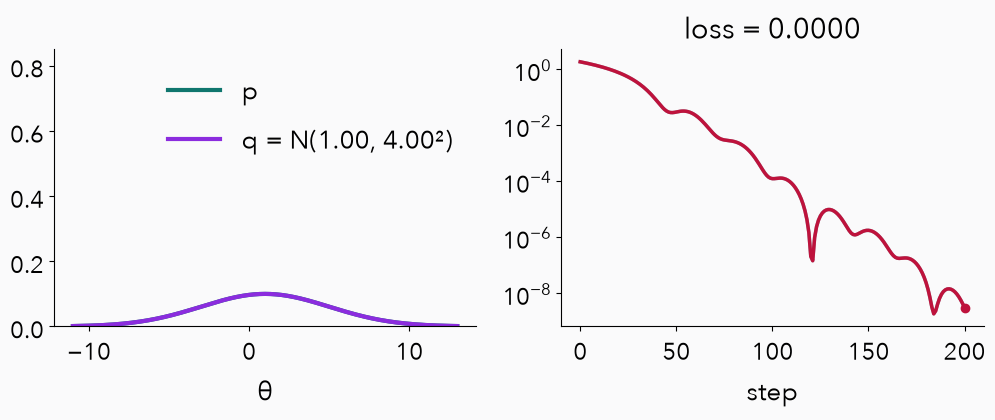

In [29]:
def show_step(step=0):
    _, m_, s_, l_ = history[step]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    axes[0].plot(theta_grid, p.log_prob(theta_grid).exp(), color=C["p"], lw=3, label="p")
    axes[0].plot(theta_grid, Normal(m_, s_).log_prob(theta_grid).exp(), color=C["q"], lw=3, label=f"q = N({m_:.2f}, {s_:.2f}²)")
    axes[0].set(xlabel="θ", ylim=(0, .85)); axes[0].legend(frameon=False)
    axes[1].semilogy(H_[:, 0], H_[:, 3], color="#9CA3AF"); axes[1].semilogy(H_[:step + 1, 0], H_[:step + 1, 3], color=C["loss"])
    axes[1].plot(step, l_, "o", color=C["loss"]); axes[1].set(xlabel="step", title=f"loss = {l_:.4f}")
    plt.show()
try:
    from ipywidgets import interact, IntSlider
    interact(show_step, step=IntSlider(value=0, min=0, max=200, step=1, description="step"))
except ImportError:
    print("No ipywidgets here: showing steps 0, 50 and 200 instead.")
    for step_ in (0, 50, 200):
        show_step(step_)

### 3.3 Two dimensions: three covariance families

Slides: [3.3 Three covariance families](https://nipunbatra.github.io/generative/lectures/lecture1/#cov-families/1) · [watch them fit](https://nipunbatra.github.io/generative/lectures/lecture1/#cov-fit/1) · [a q that cannot tilt shrinks](https://nipunbatra.github.io/generative/lectures/lecture1/#two-d/1)

In two dimensions a Gaussian $q=\mathcal N(\mathbf m,\Sigma)$ needs a covariance matrix. Three common families:

| family | $\Sigma$ | numbers in $\Sigma$, $d=2$ | for $d$ parameters | contours |
|---|---|---|---|---|
| isotropic | $s^2I$ | 1 | 1 | circles |
| diagonal (mean-field) | $\operatorname{diag}(s_1^2,s_2^2)$ | 2 | $d$ | axis-aligned ellipses |
| full | $LL^\top$, $L$ lower-triangular | 3 | $d(d+1)/2$ | any ellipse |

Target: $p=\mathcal N\big(\mathbf 0,\Sigma_p\big)$ with widths $1.5$ and $0.75$ and correlation $0.8$. All three start from the same random $q$ (seed 33) and minimise $\mathrm{KL}(q\|p)$ with Adam. Under $\mathrm{KL}(q\|p)$ the best diagonal $q$ takes the target’s **conditional** widths $\sigma_i\sqrt{1-\rho^2}$, and the best isotropic $q$ takes $s^2=d/\operatorname{tr}(\Sigma_p^{-1})$: both shrink to fit inside the tilted ellipse.

iso : mean (-0.000, -0.000), Σ = [[0.324, 0.000], [0.000, 0.324]], KL = 0.7340
diag: mean (-0.000, -0.000), Σ = [[0.810, 0.000], [0.000, 0.202]], KL = 0.5108
full: mean (-0.000, -0.000), Σ = [[2.250, 0.900], [0.900, 0.562]], KL = 0.0000
analytic: {'iso_sd': 0.5692, 'diag_sd': [0.9, 0.45], 'iso_kl': 0.734, 'diag_kl': 0.5108, 'full_kl': 0.0}


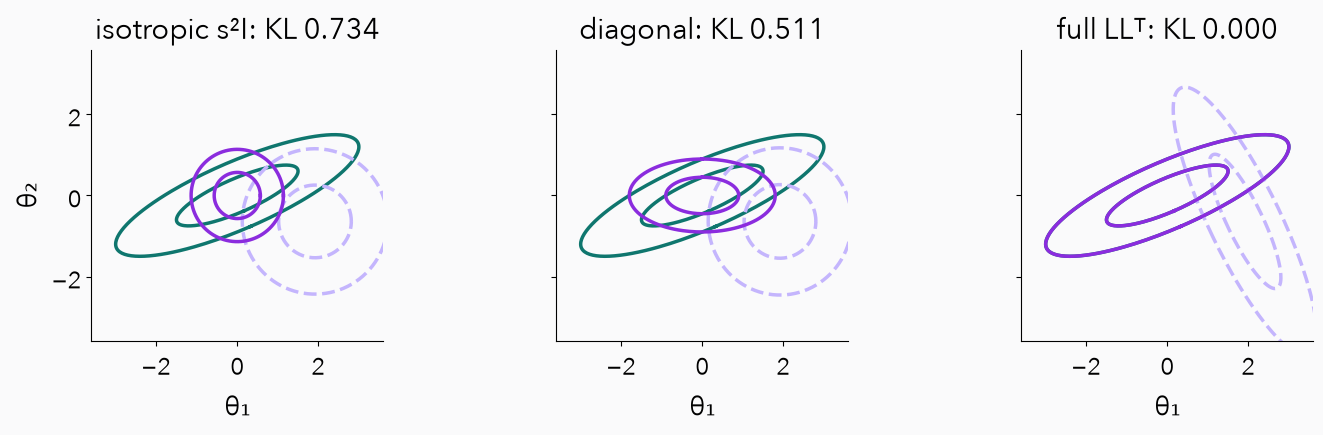

In [30]:
sd_p, rho_p = torch.tensor([1.5, .75]), .8
cov_p = torch.tensor([[sd_p[0] ** 2, rho_p * sd_p[0] * sd_p[1]], [rho_p * sd_p[0] * sd_p[1], sd_p[1] ** 2]])
p2 = dist.MultivariateNormal(torch.zeros(2), cov_p)
g = torch.Generator().manual_seed(33)          # one random start, shared by all three families
start_mean, start_log_sd, start_off = 1.6 * torch.randn(2, generator=g), .35 * torch.randn(2, generator=g), .6 * torch.randn(1, generator=g)
def scale_tril(kind, raw):
    if kind == "iso":
        return raw[0].exp() * torch.eye(2)
    if kind == "diag":
        return torch.diag(raw.exp())
    return torch.stack([torch.stack([raw[0].exp(), torch.tensor(0.)]), torch.stack([raw[2], raw[1].exp()])])
def fit_cov(kind, steps=600, lr=.05, every=5):
    init = {"iso": start_log_sd.mean()[None], "diag": start_log_sd, "full": torch.cat([start_log_sd, start_off])}[kind]
    mean = torch.nn.Parameter(start_mean.clone()); raw = torch.nn.Parameter(init.clone())
    opt = torch.optim.Adam([mean, raw], lr=lr); frames = []
    for step in range(steps + 1):
        q = dist.MultivariateNormal(mean, scale_tril=scale_tril(kind, raw))
        loss = dist.kl_divergence(q, p2)
        if step % every == 0:
            S_ = q.covariance_matrix
            frames.append([step, number(mean[0]), number(mean[1]), number(S_[0, 0]), number(S_[0, 1]), number(S_[1, 1]), number(loss)])
        if step == steps:
            break
        opt.zero_grad(); loss.backward(); opt.step()
    return frames
cov_runs = {kind: fit_cov(kind) for kind in ["iso", "diag", "full"]}
prec = torch.linalg.inv(cov_p)
iso_var = 2 / number(prec.trace())
analytic = dict(iso_sd=math.sqrt(iso_var), diag_sd=[number(1 / prec[k, k].sqrt()) for k in range(2)],
    iso_kl=.5 * (number(torch.logdet(cov_p)) - 2 * math.log(iso_var)), diag_kl=-.5 * math.log(1 - rho_p ** 2), full_kl=0.)
final = {k: v[-1] for k, v in cov_runs.items()}
assert abs(math.sqrt(final["iso"][3]) - analytic["iso_sd"]) < 1e-3 and abs(final["iso"][6] - analytic["iso_kl"]) < 1e-5
assert max(abs(math.sqrt(final["diag"][3 + 2 * k]) - analytic["diag_sd"][k]) for k in range(2)) < 1e-3
assert abs(final["diag"][6] - analytic["diag_kl"]) < 1e-5 and final["full"][6] < 1e-5
fixtures["story"]["cov3"] = dict(target=dict(mean=[0., 0.], sd=sd_p.tolist(), rho=rho_p, cov=cov_p.tolist()),
    start=dict(seed=33, mean=start_mean.tolist(), sd=start_log_sd.exp().tolist(), off=number(start_off)),
    optimiser="Adam", lr=.05, steps=600, every=5, analytic=analytic, runs=cov_runs)
for kind, f_ in final.items():
    print(f"{kind:4s}: mean ({f_[1]: .3f}, {f_[2]: .3f}), Σ = [[{f_[3]:.3f}, {f_[4]:.3f}], [{f_[4]:.3f}, {f_[5]:.3f}]], KL = {f_[6]:.4f}")
print("analytic:", {k: (round(v, 4) if isinstance(v, float) else [round(x, 4) for x in v]) for k, v in analytic.items()})
def ellipse(ax, mean, S_, color, ls="-"):
    vals, vecs = torch.linalg.eigh(torch.tensor(S_))
    t = torch.linspace(0, 2 * math.pi, 200)
    for r in (1, 2):
        pts = torch.tensor(mean)[:, None] + r * vecs @ torch.diag(vals.sqrt()) @ torch.stack([t.cos(), t.sin()])
        ax.plot(pts[0], pts[1], color=color, ls=ls)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
for ax, (kind, title) in zip(axes, [("iso", "isotropic s²I"), ("diag", "diagonal"), ("full", "full LLᵀ")]):
    first_, last_ = cov_runs[kind][0], cov_runs[kind][-1]
    ellipse(ax, [0., 0.], cov_p.tolist(), C["p"])
    ellipse(ax, first_[1:3], [[first_[3], first_[4]], [first_[4], first_[5]]], "#C4B5FD", "--")
    ellipse(ax, last_[1:3], [[last_[3], last_[4]], [last_[4], last_[5]]], C["q"])
    ax.set(title=f"{title}: KL {last_[6]:.3f}", aspect="equal", xlim=(-3.6, 3.6), ylim=(-3.6, 3.6), xlabel="θ₁")
axes[0].set(ylabel="θ₂")
savefig("cov-families-fit")

### 3.4 A target with no formula: a mixture of Gaussians

Slides: [3.4 What a mixture is](https://nipunbatra.github.io/generative/lectures/lecture1/#mixture-what/1) · [draw from it yourself](https://nipunbatra.github.io/generative/lectures/lecture1/#mixture-sample/1) · [no formula for the KL](https://nipunbatra.github.io/generative/lectures/lecture1/#mixture-no-formula/1) · [optimise it: q does not move](https://nipunbatra.github.io/generative/lectures/lecture1/#now-optimise/1)

A **mixture of Gaussians** generates $\theta$ in two steps: first pick a bump $z$ with probabilities $\pi_k$, then draw $\theta$ from that bump’s Gaussian:

$$z\sim\mathrm{Categorical}(\pi),\qquad\theta\mid z\sim\mathcal N(\mu_z,\sigma_z^2).$$

Adding up over the bump we did not see gives the density, a weighted sum of bells:

$$p(\theta)=\sum_{k}\pi_k\,\mathcal N(\theta;\mu_k,\sigma_k^2)=0.5\,\mathcal N(\theta;-0.2,0.4^2)+0.5\,\mathcal N(\theta;1,0.5^2)$$

(the PML 2023 example). $\log p(\theta)$ is easy to evaluate. $\mathrm{KL}(q\|p)$ from a Gaussian $q$ has no formula, but it is still an average under $q$, so we can sample it.

bump 1 picked 995 times, bump 2 1005 times, out of 2,000


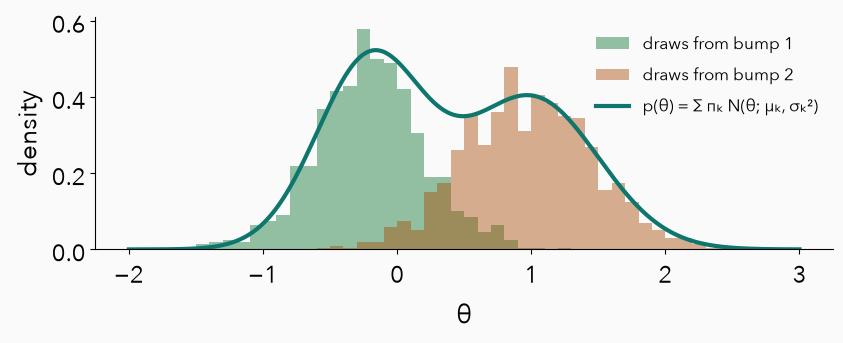

In [31]:
pi_mix, means_mix, sds_mix = torch.tensor([.5, .5]), torch.tensor([-.2, 1.]), torch.tensor([.4, .5])
torch.manual_seed(31)
S_mix = 2000
z = dist.Categorical(probs=pi_mix).sample((S_mix,))              # step 1: which bump?
theta_mix = dist.Normal(means_mix[z], sds_mix[z]).sample()        # step 2: a draw from that bump
counts = torch.bincount(z, minlength=2)
print(f"bump 1 picked {int(counts[0])} times, bump 2 {int(counts[1])} times, out of {S_mix:,}")
fixtures["story"]["mixture_sampling"] = dict(seed=31, draws=S_mix, counts=counts.tolist(),
    weights=pi_mix.tolist(), means=means_mix.tolist(), sds=sds_mix.tolist())
grid_m = torch.linspace(-2, 3, 401)
def mixture_density(t):
    return (pi_mix * dist.Normal(means_mix, sds_mix).log_prob(t[:, None]).exp()).sum(-1)
fig, ax = plt.subplots(figsize=(8.8, 3.8))
bins = np.linspace(-2, 3, 51)
for k, col in enumerate(["#147737", "#AA4E08"]):
    ax.hist(theta_mix[z == k], bins=bins, color=col, alpha=.45, label=f"draws from bump {k + 1}", weights=np.full(int(counts[k]), 1 / (S_mix * (bins[1] - bins[0]))))
ax.plot(grid_m, mixture_density(grid_m), color=C["p"], lw=3, label="p(θ) = Σ πₖ N(θ; μₖ, σₖ²)")
ax.set(xlabel="θ", ylabel="density"); ax.legend(frameon=False, fontsize=12)
savefig("mixture-sampling")

No KL(p || q) is implemented for p type Normal and q type MixtureSameFamily


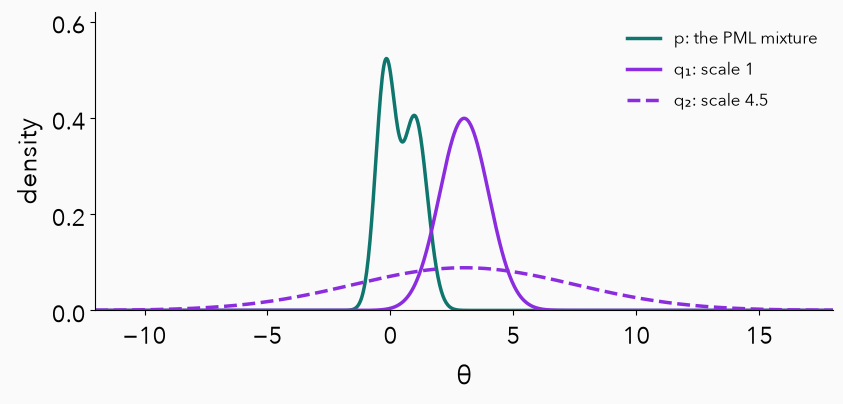

In [32]:
mixture = dist.MixtureSameFamily(
    dist.Categorical(probs=torch.tensor([.5,.5])),
    dist.Normal(torch.tensor([-.2,1.]), torch.tensor([.4,.5])))
mix_q1, mix_q2 = dist.Normal(3.,1.), dist.Normal(3.,4.5)
try:
    dist.kl_divergence(mix_q1,mixture)
    unsupported = "This runtime implements the pair."
except NotImplementedError as exc:
    unsupported = str(exc)
print(unsupported)
xx = torch.linspace(-12,18,901)
fig, ax = plt.subplots(figsize=(8.8,4.4))
ax.plot(xx,mixture.log_prob(xx).exp(),color=C["p"],label="p: the PML mixture")
ax.plot(xx,mix_q1.log_prob(xx).exp(),color=C["q"],label="q₁: scale 1")
ax.plot(xx,mix_q2.log_prob(xx).exp(),color=C["q"],ls="--",label="q₂: scale 4.5")
ax.set(xlim=(-12,18),ylim=(0,.62),xlabel="θ",ylabel="density")
ax.legend(frameon=False,fontsize=12)
savefig("mixture-candidates")

In [33]:
mix_results=[]
for i,q in enumerate([mix_q1,mix_q2],1):
    value,se=mc_kl(q,mixture,100_000,401+i)
    # Independent numerical integral, using a wide q-dependent domain.
    grid=torch.linspace(number(q.loc-12*q.scale),number(q.loc+12*q.scale),200_001)
    integrand=q.log_prob(grid).exp()*(q.log_prob(grid)-mixture.log_prob(grid))
    numerical=torch.trapezoid(integrand,grid)
    assert abs(number(value-numerical))<5*number(se)
    mix_results.append(dict(id=f"q{i}",mu=3.,sigma=number(q.scale),mc=number(value),
        standard_error=number(se),samples=100_000,seed=401+i,quadrature=number(numerical)))
    print(f"q{i}: MC estimate {value:.5f} ± {se:.5f} (one standard error); numerical integral {numerical:.5f}")
fixtures["mixture"]={"weights":[.5,.5],"means":[-.2,1.],"scales":[.4,.5],
                     "unsupported_message":unsupported,"candidates":mix_results}

q1: MC estimate 9.54484 ± 0.02625 (one standard error); numerical integral 9.48902
q2: MC estimate 45.02336 ± 0.21184 (one standard error); numerical integral 45.15153


#### Optimise it with `sample()`: is this a bug?

Slides: [the code runs, and q does not move](https://nipunbatra.github.io/generative/lectures/lecture1/#now-optimise/1)

Fit a Gaussian to the mixture from $\mathcal N(6,0.1^2)$, with 5,000 draws per step and plain gradient descent, using the sampled KL as the loss. With `sample()` the code runs without an error or a warning, but $q$ barely moves. Is this a bug? Hold the question; 3.5 finds the missing piece.

In [34]:
def mixture_kl_quadrature(q):
    g = torch.linspace(-10, 12, 20_001)
    lq = q.log_prob(g)
    return number(torch.trapezoid(lq.exp() * (lq - mixture.log_prob(g)), g))
def fit_mixture(use_rsample, steps=400, draws=5000, seed=4004, dense=120, every=5):
    torch.manual_seed(seed)
    m = torch.nn.Parameter(torch.tensor(6.)); rho = torch.nn.Parameter(torch.tensor(math.log(.1)))
    opt = torch.optim.SGD([m, rho], lr=.05); frames = []
    for step in range(steps + 1):
        q = dist.Normal(m, rho.exp())
        theta_s = q.rsample((draws,)) if use_rsample else q.sample((draws,))
        loss = (q.log_prob(theta_s) - mixture.log_prob(theta_s)).mean()
        if step <= dense or step % every == 0:  # dense frames while q moves, for the slide animation
            frames.append([step, number(m), number(rho.exp()), number(loss),
                           mixture_kl_quadrature(dist.Normal(m.detach(), rho.detach().exp()))])
        if step == steps:
            break
        opt.zero_grad(); loss.backward(); opt.step()
    return frames
mix_sample = fit_mixture(False)
_, m_, s_, est, exact_ = mix_sample[-1]
print(f"sample(): after 400 steps q = N({m_:.3f}, {s_:.3f}²); the KL is still about {exact_:.0f}")

sample(): after 400 steps q = N(6.076, 0.097²); the KL is still about 53


### 3.5 The reparameterisation trick

Slides: [3.5 The gradient never reaches q](https://nipunbatra.github.io/generative/lectures/lecture1/#missing-path/1) · [θ = μ + σε](https://nipunbatra.github.io/generative/lectures/lecture1/#reparam/1) · [what a fixed ε does](https://nipunbatra.github.io/generative/lectures/lecture1/#reparam-picture/1) · [side by side](https://nipunbatra.github.io/generative/lectures/lecture1/#reparam-compare/1) · [change one word](https://nipunbatra.github.io/generative/lectures/lecture1/#rsample-fit/1)

Draw the computation as a graph with **deterministic** nodes (computed from their inputs) and **stochastic** nodes (drawn at random), as in [Lilian Weng’s VAE post](https://lilianweng.github.io/posts/2018-08-12-vae/), after Kingma’s NIPS 2015 talk. With `sample()`, $\theta$ is a stochastic node fed by $\mu,\sigma$: autograd cannot see how $\theta$ would move if $\mu$ or $\sigma$ changed, so the gradient stops there. `Normal.sample()` returns a draw without that path; asking the draw itself for a gradient fails.

A loss containing `q.log_prob(draw)` still produces *some* gradient, through the explicit $\mu,\sigma$ in the log density. **A gradient tensor alone does not prove the missing path was handled.**

In [35]:
torch.manual_seed(12)
mu=torch.tensor(0.,requires_grad=True)
sigma=torch.tensor(2.,requires_grad=True)
q=dist.Normal(mu,sigma)
draw=q.sample()
try:
    draw.backward()
    sample_error="No error"
except RuntimeError as exc:
    sample_error=str(exc)
print("sample.requires_grad:",draw.requires_grad)
print("sample.backward():",sample_error)

# Same chosen noise lets us compare estimators without confounding them with new draws.
torch.manual_seed(13)
eps=torch.randn(50_000)
detached=(mu+sigma*eps).detach()
wrong_loss=(q.log_prob(detached)-p.log_prob(detached)).mean()
wrong_grads=torch.autograd.grad(wrong_loss,(mu,sigma))
correct_draw=mu+sigma*eps
path_loss=(q.log_prob(correct_draw)-p.log_prob(correct_draw)).mean()
path_grads=torch.autograd.grad(path_loss,(mu,sigma))
exact_grads=((0.-1.)/16,2./16-1./2)
fixtures["gradients"]={"sample_seed":12,"sample_requires_grad":draw.requires_grad,
    "sample_backward_error":sample_error,"comparison_seed":13,"samples":50000,
    "detached_sample_grads":[number(v) for v in wrong_grads],
    "pathwise_grads":[number(v) for v in path_grads],"analytic_grads":list(exact_grads)}
print("Naive detached-sample grads:",[number(v) for v in wrong_grads])
print("Pathwise grads:",[number(v) for v in path_grads])
print("Analytic reference:",exact_grads)

sample.requires_grad: False
sample.backward(): element 0 of tensors does not require grad and does not have a grad_fn
Naive detached-sample grads: [0.001281465829292653, -0.0002523191477337705]
Pathwise grads: [-0.06217963354267684, -0.375223263015595]
Analytic reference: (-0.0625, -0.375)


The detached-sample derivative above leaves out how changing $q$ changes where its draws land. A properly built **score-function estimator** is another valid route (optional slide); the fix used for Gaussians, and in every VAE, moves the randomness outside the parameters.

#### Move the randomness outside: $\theta=\mu+\sigma\epsilon$

$$\epsilon\sim\mathcal N(0,1),\quad \theta=\mu+\sigma\epsilon,\quad
\frac{\partial \theta}{\partial\mu}=1,\quad
\frac{\partial \theta}{\partial\sigma}=\epsilon.$$

Now $\theta$ is a deterministic node, and the only stochastic node, $\epsilon$, has no parameters, so the gradient flows from the loss through $\theta$ back to $\mu$ and $\sigma$. Hold one $\epsilon$ fixed while checking derivatives; training uses fresh noise. The chosen $\epsilon=-0.75$ below makes the arithmetic visible; it is not a random sample.

In [36]:
mu=torch.tensor(0.,requires_grad=True)
sigma=torch.tensor(2.,requires_grad=True)
eps_chosen=torch.tensor(-.75)
draw=mu+sigma*eps_chosen
du=torch.autograd.grad(draw,(mu,sigma),retain_graph=True)
scalar_loss=(draw-1).square()
dL=torch.autograd.grad(scalar_loss,(mu,sigma))
fixtures["gradients"]["scalar"]=dict(mu=0.,sigma=2.,epsilon=-.75,u=number(draw),
    loss=number(scalar_loss),du_dmu=number(du[0]),du_dsigma=number(du[1]),
    dloss_dmu=number(dL[0]),dloss_dsigma=number(dL[1]))
print(fixtures["gradients"]["scalar"])

{'mu': 0.0, 'sigma': 2.0, 'epsilon': -0.75, 'u': -1.5, 'loss': 6.25, 'du_dmu': 1.0, 'du_dsigma': -0.75, 'dloss_dmu': -5.0, 'dloss_dsigma': 3.75}


`Normal.rsample()` uses a differentiable draw. To check the derivative numerically, reuse one fixed noise array in both finite-difference evaluations.

In [37]:
torch.manual_seed(88)
eps_fixed=torch.randn(2048)
def fixed_noise_loss(mu_value,sigma_value):
    q=dist.Normal(mu_value,sigma_value)
    x=mu_value+sigma_value*eps_fixed
    return (q.log_prob(x)-p.log_prob(x)).mean()
mu=torch.tensor(0.,requires_grad=True)
sigma=torch.tensor(2.,requires_grad=True)
g=torch.autograd.grad(fixed_noise_loss(mu,sigma),(mu,sigma))
h=1e-5
fd_mu=(fixed_noise_loss(mu.detach()+h,sigma.detach())-fixed_noise_loss(mu.detach()-h,sigma.detach()))/(2*h)
fd_sigma=(fixed_noise_loss(mu.detach(),sigma.detach()+h)-fixed_noise_loss(mu.detach(),sigma.detach()-h))/(2*h)
assert abs(number(g[0]-fd_mu))<1e-8
assert abs(number(g[1]-fd_sigma))<1e-8
torch.manual_seed(88)
rs=dist.Normal(mu,sigma).rsample((2048,))
assert torch.allclose(rs,mu+sigma*eps_fixed)
fixtures["gradients"]["finite_difference"]=dict(seed=88,samples=2048,h=h,
    autograd=[number(v) for v in g],finite_difference=[number(fd_mu),number(fd_sigma)])
print(fixtures["gradients"]["finite_difference"])

{'seed': 88, 'samples': 2048, 'h': 1e-05, 'autograd': [-0.06246599500273631, -0.3722226142944757], 'finite_difference': [-0.06246599500159266, -0.37222261430047693]}


#### Change one word: `rsample()` fits the mixture

Slides: [change one word](https://nipunbatra.github.io/generative/lectures/lecture1/#rsample-fit/1)

The same loop, the same start, the same seed, with `q.rsample` in place of `q.sample`. (With Adam, the stuck `sample()` run wanders aimlessly instead of standing still; it still never fits.)

sample(): final N(6.076, 0.097^2), MC KL 53.372, quadrature KL 53.380
rsample(): final N(0.429, 0.720^2), MC KL 0.061, quadrature KL 0.056


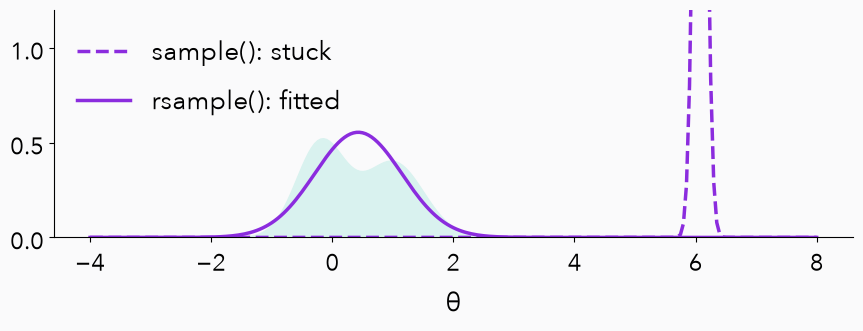

In [38]:
mix_rsample = fit_mixture(True)
x_mix = torch.linspace(-4, 8, 241)
fixtures["story"]["mixfit"] = dict(start=[6., .1], optimiser="SGD", lr=.05, steps=400, draws=5000, seed=4004,
    rsample=mix_rsample, sample=mix_sample, x=x_mix.tolist(), p=mixture.log_prob(x_mix).exp().tolist())
for name, frames in [("sample()", mix_sample), ("rsample()", mix_rsample)]:
    _, m_, s_, est, exact = frames[-1]
    print(f"{name}: final N({m_:.3f}, {s_:.3f}^2), MC KL {est:.3f}, quadrature KL {exact:.3f}")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(x_mix, 0, mixture.log_prob(x_mix).exp(), color="#D9F2EF")
for frames, style, label in [(mix_sample, "--", "sample(): stuck"), (mix_rsample, "-", "rsample(): fitted")]:
    _, m_, s_, _, _ = frames[-1]
    ax.plot(x_mix, dist.Normal(m_, s_).log_prob(x_mix).exp(), color=C["q"], ls=style, label=label)
ax.set(ylim=(0, 1.2), xlabel="θ")
ax.legend(frameon=False)
savefig("mixture-fit")

### 3.6 Which direction of KL?

Slides: [3.6 The price: reverse KL picks one bump](https://nipunbatra.github.io/generative/lectures/lecture1/#fwdrev/1)

Target $p=0.7\,\mathcal N(-2,w^2)+0.3\,\mathcal N(2,w^2)$. Fit a Gaussian $q$ by gradient descent on each direction of the KL, computed on a grid. $\mathrm{KL}(p\|q)$ averages under $p$, so $q$ must cover both bumps. $\mathrm{KL}(q\|p)$ averages under $q$, so mass in the gap is expensive and $q$ settles on one bump; which one depends on where it starts.

bump width 1.0: fwd: N(-0.80, 2.09^2), KL 0.180; revl: N(-0.78, 1.90^2), KL 0.237; revr: N(-0.78, 1.90^2), KL 0.237


bump width 0.5: fwd: N(-0.80, 1.90^2), KL 0.724; revl: N(-2.00, 0.50^2), KL 0.357; revr: N(2.00, 0.50^2), KL 1.204


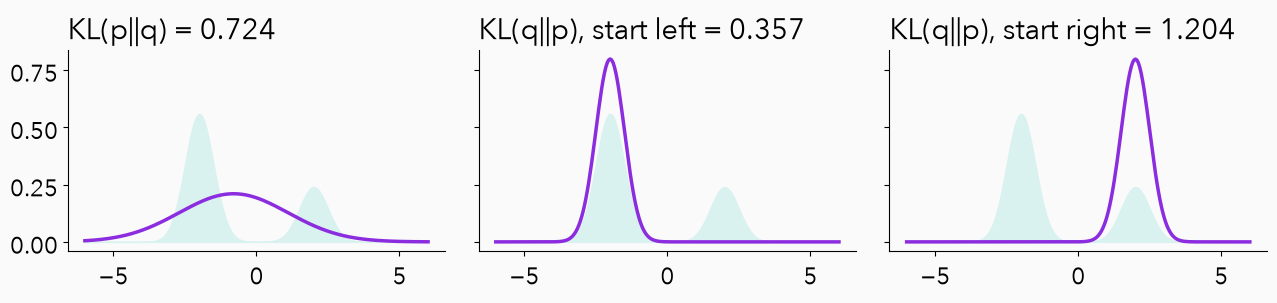

In [39]:
def bump_mixture(width):
    return dist.MixtureSameFamily(dist.Categorical(probs=torch.tensor([.7, .3])),
        dist.Normal(torch.tensor([-2., 2.]), torch.tensor([width, width])))
grid_fr = torch.linspace(-8, 8, 2001)
x_fr = torch.linspace(-6, 6, 241)
def fit_direction(target, direction, start, steps=300, lr=.05, every=2):
    m = torch.nn.Parameter(torch.tensor(start[0]))
    rho = torch.nn.Parameter(torch.tensor(math.log(start[1])))
    opt = torch.optim.Adam([m, rho], lr=lr); frames = []
    for step in range(steps + 1):
        q = dist.Normal(m, rho.exp())
        loss = grid_kl(q, target, grid_fr) if direction == "reverse" else grid_kl(target, q, grid_fr)
        if step % every == 0:
            frames.append([step, number(m), number(rho.exp()), number(loss)])
        if step == steps:
            break
        opt.zero_grad(); loss.backward(); opt.step()
    return frames
fwdrev = {"x": x_fr.tolist(), "start": {"fwd": [.5, .6], "revl": [-.5, .6], "revr": [.5, .6]}, "steps": 300, "lr": .05}
for width in [1.0, 0.5]:
    target = bump_mixture(width)
    runs = {"fwd": fit_direction(target, "forward", (.5, .6)),
            "revl": fit_direction(target, "reverse", (-.5, .6)),
            "revr": fit_direction(target, "reverse", (.5, .6))}
    fwdrev[str(width)] = dict(p=target.log_prob(x_fr).exp().tolist(), **runs)
    print(f"bump width {width}: " + "; ".join(
        f"{k}: N({v[-1][1]:.2f}, {v[-1][2]:.2f}^2), KL {v[-1][3]:.3f}" for k, v in runs.items()))
fixtures["story"]["fwdrev"] = fwdrev
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
narrow = bump_mixture(.5)
for ax, key, title in zip(axes, ["fwd", "revl", "revr"], ["KL(p||q)", "KL(q||p), start left", "KL(q||p), start right"]):
    _, m_, s_, k_ = fwdrev["0.5"][key][-1]
    ax.fill_between(x_fr, 0, narrow.log_prob(x_fr).exp(), color="#D9F2EF")
    ax.plot(x_fr, dist.Normal(m_, s_).log_prob(x_fr).exp(), color=C["q"])
    ax.set_title(f"{title} = {k_:.3f}", loc="left")
savefig("forward-reverse")

## Part 4 · Back to Bayes: the ELBO

Slides: [Part 4](https://nipunbatra.github.io/generative/lectures/lecture1/#can-we/1). The real target is the posterior, which we cannot write down because of the evidence. Substituting Bayes’ rule into the KL, one rule per line, turns the unknown $\log p(\mathcal D)$ into a constant and leaves an objective we can compute: the ELBO. A careful written version: [Gregory Gundersen, “The ELBO in Variational Inference”](https://www.gregorygundersen.com/blog/2021/04/16/variational-inference/).

### 4.1 Deriving the ELBO, one rule per line

Slides: [4.1 Minimise KL to the posterior directly?](https://nipunbatra.github.io/generative/lectures/lecture1/#can-we/1) · [step by step](https://nipunbatra.github.io/generative/lectures/lecture1/#elbo-step1/1) · [why KL ≥ 0](https://nipunbatra.github.io/generative/lectures/lecture1/#kl-nonneg/1) · [why “lower bound”](https://nipunbatra.github.io/generative/lectures/lecture1/#elbo-bound/1)

| step | line | rule used |
|---|---|---|
| 1 | $\mathrm{KL}\big(q\,\|\,p(\theta\mid\mathcal D)\big)=\mathbb E_{q}\big[\log q(\theta)-\log p(\theta\mid\mathcal D)\big]$ | definition of KL: average the log ratio under $q$ |
| 2 | $\log p(\theta\mid\mathcal D)=\log p(\mathcal D\mid\theta)+\log p(\theta)-\log p(\mathcal D)$ | Bayes’ rule, then $\log\frac{ab}{c}=\log a+\log b-\log c$ |
| 3 | $\mathrm{KL}=\mathbb E_q\big[\log q(\theta)-\log p(\mathcal D\mid\theta)-\log p(\theta)+\log p(\mathcal D)\big]$ | substitute line 2 into line 1 |
| 4 | $\mathrm{KL}=\mathbb E_q\big[\log q(\theta)-\log p(\mathcal D\mid\theta)-\log p(\theta)\big]+\log p(\mathcal D)$ | $\log p(\mathcal D)$ contains no $\theta$: the average of a constant is the constant, $\mathbb E_q[f(\theta)+c]=\mathbb E_q[f(\theta)]+c$ |
| 5 | $\log p(\mathcal D)=\underbrace{\mathbb E_q\big[\log p(\mathcal D\mid\theta)+\log p(\theta)-\log q(\theta)\big]}_{\mathrm{ELBO}(q)}+\mathrm{KL}\big(q\,\|\,p(\theta\mid\mathcal D)\big)$ | move terms across; name the computable part |

**What each piece is.** $\log p(\mathcal D)$, the log evidence: one fixed number for this model and these data; $q$ cannot change it. $\mathrm{ELBO}(q)$: computable for any $q$ from draws, the likelihood, the prior and $\log q$. $\mathrm{KL}(q\|p(\theta\mid\mathcal D))$: unknown, but **never negative**. So $\mathrm{ELBO}(q)\le\log p(\mathcal D)$: a *lower bound* on the log evidence, which is where the name comes from. “Lower bound” does **not** mean the ELBO is $\ge0$, and it says nothing about the sign of $\log p(\mathcal D)$. For the coin below, $\log p(\mathcal D)=-21.4$: the log of a probability, which is at most 1, is never positive. For our network the data are continuous, so $p(\mathcal D\mid\theta)$ is a **density**, which can exceed 1: $\log p(\mathcal D\mid\theta_A)=+12.2$, while $\log p(\mathcal D)\approx-1.4$. The sign is not the point; the order is: ELBO $\le\log p(\mathcal D)$ always. Since $\log p(\mathcal D)$ is fixed, raising the ELBO by one nat lowers the KL by exactly one nat.

In practice we maximise the ELBO (minimise its negative) using only the **joint** $p(\mathcal D\mid\theta)\,p(\theta)$; the expectation is estimated by Monte Carlo. A finite-sample ELBO estimate can land above $\log p(\mathcal D)$ on an unlucky draw; it is the exact expectation that is the lower bound (optional slide: [a noisy ELBO estimate can cross the evidence](https://nipunbatra.github.io/generative/lectures/lecture1/?all#optional-noisy-elbo/1)).

### 4.2 Check it where the answer is known: a coin

Slides: [4.2 Check the identity on a coin](https://nipunbatra.github.io/generative/lectures/lecture1/#elbo-slider/1) · optional: [a check with an answer key](https://nipunbatra.github.io/generative/lectures/lecture1/#answer-key/1)

Use a Beta(5,3) prior and **one ordered sequence** with 17 heads and 13 tails. Any order with these counts has the same sequence likelihood:

$$p(\mathcal D\mid r)=r^{17}(1-r)^{13}.$$

There is no binomial coefficient in this convention. The known posterior Beta(22,16) and known evidence are for **validation**, not inputs to the optimiser.

In [40]:
tosses="HHTHTHTHHHTTHTHHTHTTHHHTTHTHTH"
assert len(tosses)==30 and tosses.count("H")==17 and tosses.count("T")==13
prior=dist.Beta(torch.tensor(5.),torch.tensor(3.))
posterior=dist.Beta(torch.tensor(22.),torch.tensor(16.))
heads,tails=17,13
def log_joint(r):
    return prior.log_prob(r)+heads*torch.log(r)+tails*torch.log1p(-r)
def log_beta(a,b):
    return torch.lgamma(a)+torch.lgamma(b)-torch.lgamma(a+b)
log_evidence=log_beta(torch.tensor(22.),torch.tensor(16.))-log_beta(torch.tensor(5.),torch.tensor(3.))
def direct_beta_elbo(a,b):
    a,b=torch.as_tensor(a),torch.as_tensor(b)
    mean_log_r=torch.digamma(a)-torch.digamma(a+b)
    mean_log_1mr=torch.digamma(b)-torch.digamma(a+b)
    expected_likelihood=heads*mean_log_r+tails*mean_log_1mr
    expected_prior=4*mean_log_r+2*mean_log_1mr-log_beta(torch.tensor(5.),torch.tensor(3.))
    expected_log_q=(a-1)*mean_log_r+(b-1)*mean_log_1mr-log_beta(a,b)
    return expected_likelihood+expected_prior-expected_log_q
coin_candidates=[]
for a,b in [(10.,10.),(30.,20.),(22.,16.)]:
    q=dist.Beta(torch.tensor(a),torch.tensor(b))
    elbo=direct_beta_elbo(a,b)
    gap=dist.kl_divergence(q,posterior)
    assert abs(number(elbo+gap-log_evidence))<1e-10
    coin_candidates.append(dict(a=a,b=b,elbo=number(elbo),posterior_kl=number(gap)))
    print(f"Beta({a:g},{b:g}): ELBO={elbo:.9f}; posterior KL={gap:.9f}; sum={elbo+gap:.9f}")
fixtures["coin"]={"ordered_sequence":tosses,"heads":heads,"tails":tails,
    "prior":[5,3],"posterior":[22,16],"log_evidence":number(log_evidence),
    "candidates":coin_candidates,"convention":"ordered sequence; no binomial coefficient"}

Beta(10,10): ELBO=-22.020154134; posterior KL=0.622912312; sum=-21.397241822
Beta(30,20): ELBO=-21.448585391; posterior KL=0.051343569; sum=-21.397241822
Beta(22,16): ELBO=-21.397241822; posterior KL=0.000000000; sum=-21.397241822


#### Live demo · joint-only optimisation, about 3–4 minutes

Let $q_\psi(r)=\mathrm{Beta}(a,b)$ with $a=\exp(\psi_a)$ and $b=\exp(\psi_b)$. Both shape parameters remain positive.

For S scalar draws, `log_joint(r)` and `q.log_prob(r)` each have shape `[S]`. Their difference is averaged **once over S**. The 30 observations are already summed in the log likelihood. We do not multiply the entropy by 30 or sum the sample dimension before averaging.

`Beta.rsample()` is differentiable, but it is not the Gaussian formula $\mu+\sigma\epsilon$. PyTorch supplies an implicit reparameterisation gradient.

In [41]:
torch.manual_seed(2401)
psi=torch.nn.Parameter(torch.log(torch.tensor([10.,10.])))
optimiser=torch.optim.Adam([psi],lr=.025)
coin_trace=[]
for step in range(601):
    a,b=psi.exp()
    q=dist.Beta(a,b)
    with torch.no_grad():
        exact_elbo=direct_beta_elbo(a,b)
        exact_gap=dist.kl_divergence(q,posterior)
        coin_trace.append(dict(step=step,a=number(a),b=number(b),
                              exact_elbo=number(exact_elbo),posterior_kl=number(exact_gap)))
    if step==600: break
    r=q.rsample((512,))
    terms=log_joint(r)-q.log_prob(r)
    assert terms.shape==(512,)
    loss=-terms.mean()
    optimiser.zero_grad()
    loss.backward()
    if step==0:
        fixtures["coin"]["first_step"]=dict(a=number(a),b=number(b),
            sampled_negative_elbo=number(loss),gradient_psi=psi.grad.tolist(),
            shape=list(terms.shape),reduction="mean over 512 independent scalar r draws")
    optimiser.step()
    coin_trace[-1]["sampled_negative_elbo"]=number(loss)
assert coin_trace[-1]["posterior_kl"]<.01
assert all(r["a"]>0 and r["b"]>0 for r in coin_trace)
fixtures["coin"]["training"]={"seed":2401,"steps":600,"samples_per_step":512,
    "learning_rate":.025,"optimiser":"Adam","parameterisation":"a,b=exp(psi)",
    "objective":"negative Monte Carlo mean of log_joint(r)-log_q(r)",
    "reference_used_by_optimiser":False,"trace":coin_trace}
print("Measured final fit:",coin_trace[-1])
print("Reference Beta(22,16) was used only for diagnostics.")

Measured final fit: {'step': 600, 'a': 22.39359918744698, 'b': 16.189260387679358, 'exact_elbo': -21.39746336078113, 'posterior_kl': 0.00022153846902073226}
Reference Beta(22,16) was used only for diagnostics.


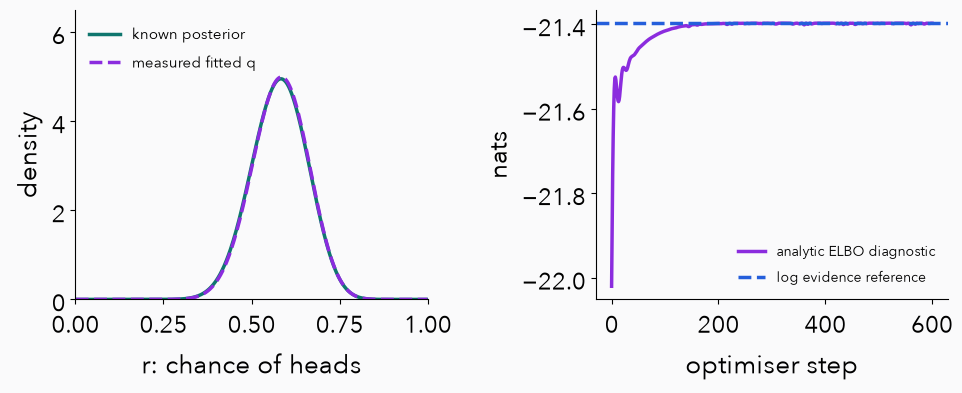

In [42]:
rr=torch.linspace(.001,.999,501)
fig,axes=plt.subplots(1,2,figsize=(10,4.3))
axes[0].plot(rr,posterior.log_prob(rr).exp(),color=C["p"],label="known posterior")
final=coin_trace[-1]
fitted=dist.Beta(final["a"],final["b"])
axes[0].plot(rr,fitted.log_prob(rr).exp(),color=C["q"],ls="--",label="measured fitted q")
axes[0].set(xlim=(0,1),ylim=(0,6.5),xlabel="r: chance of heads",ylabel="density")
axes[0].legend(frameon=False,fontsize=11)
axes[1].plot([r["step"] for r in coin_trace],[r["exact_elbo"] for r in coin_trace],
             color=C["q"],label="analytic ELBO diagnostic")
axes[1].axhline(number(log_evidence),color=C["data"],ls="--",label="log evidence reference")
axes[1].set(xlabel="optimiser step",ylabel="nats")
axes[1].legend(frameon=False,fontsize=10)
savefig("coin-fit")

#### A noisy objective is not the exact bound

The next figure compares the actual stochastic objective used during training with the analytic ELBO of the same pre-update q. Training samples change at every step. Apparent one-step movement of the noisy trace is not a certificate of improvement.

The exact posterior is in the Beta family, so exact recovery is possible in principle. A restricted family, incomplete optimisation, or local optima can prevent it in other problems. A stable training loss does not prove zero posterior KL.

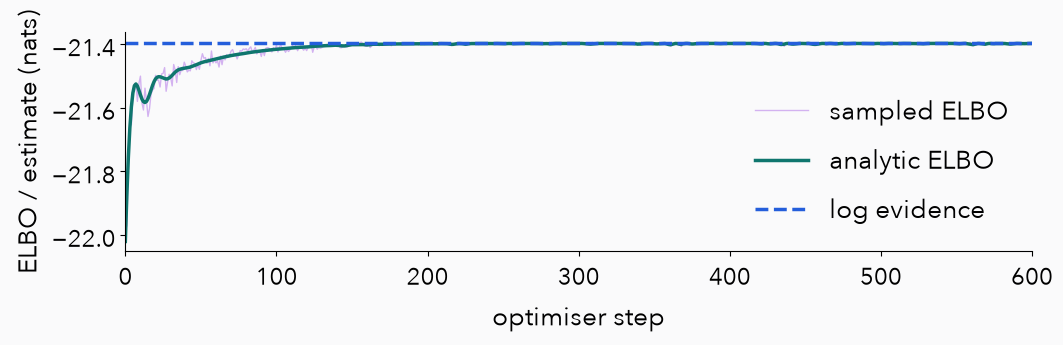

MC estimates above the exact evidence: 162


In [43]:
fig,ax=plt.subplots(figsize=(11,3.6))
steps=np.array([r["step"] for r in coin_trace[:-1]])
sampled=np.array([-r["sampled_negative_elbo"] for r in coin_trace[:-1]])
exact=np.array([r["exact_elbo"] for r in coin_trace[:-1]])
ax.plot(steps,sampled,color=C["q"],alpha=.35,lw=1,label="sampled ELBO")
ax.plot(steps,exact,color=C["p"],label="analytic ELBO")
ax.axhline(number(log_evidence),color=C["data"],ls="--",label="log evidence")
ax.set(xlim=(0,600),xlabel="optimiser step",ylabel="ELBO / estimate (nats)")
ax.legend(frameon=False,fontsize=19)
savefig("coin-noisy-objective")
fixtures["coin"]["sampled_estimates_above_evidence"]=int(np.sum(sampled>number(log_evidence)))
print("MC estimates above the exact evidence:",fixtures["coin"]["sampled_estimates_above_evidence"])

## Part 5 · Implement it

Slides: [Part 5](https://nipunbatra.github.io/generative/lectures/lecture1/#bnn-elbo-code/1). Variational inference for the tiny network from Part 1: fourteen numbers, sixteen sampled networks per step, the closed-form KL to the prior, and never $p(\mathcal D)$.

### 5.1 Variational inference for the tiny network

Slides: [5.1 The ELBO in code](https://nipunbatra.github.io/generative/lectures/lecture1/#bnn-elbo-code/1) · [press play](https://nipunbatra.github.io/generative/lectures/lecture1/#bnn-vi/1) · [what q learned](https://nipunbatra.github.io/generative/lectures/lecture1/#bnn-q/1) · [against the reference](https://nipunbatra.github.io/generative/lectures/lecture1/#bnn-vs-ref/1)

A mean-field Gaussian over the seven parameters,

$$q_\psi(\theta)=\prod_{j=1}^{7}\mathcal N(\theta_j;\mu_j,\sigma_j^2),\qquad\psi=(\mu,\rho),\ \sigma=\exp(\rho):\ 14\text{ numbers}.$$

Maximise $\mathrm{ELBO}(\psi)=\mathbb E_q[\log p(\mathcal D\mid\theta)]-\mathrm{KL}(q_\psi\,\|\,p(\theta))$. The first term is a Monte Carlo average over `rsample` draws (16 per step); the second is the closed-form Gaussian KL from Section 2, summed over the seven parameters. Five random starts; we keep the one with the highest final ELBO.

restart ELBOs [-7.18, -7.49, -7.22, -7.18, -7.3] · kept seed 0
ELBO -7.18 = E_q[log p(D|θ)] 8.10 − KL(q||prior) 15.28
log p(D) ≈ -1.43, so KL(q || posterior) ≈ 5.75 nats
predictive sd at x = −2.5, 0, 2.5: VI [0.11, 0.13, 0.11] · HMC [0.215, 0.162, 0.168]


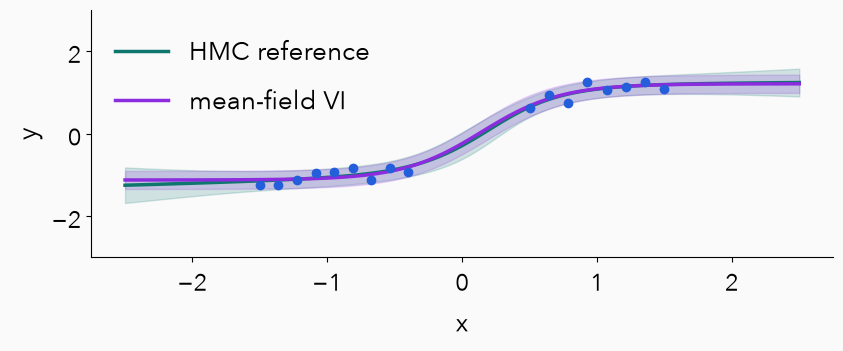

In [44]:
def fit_bnn_vi(seed, steps=4000, draws=16, lr=.02, record=False):
    torch.manual_seed(seed)
    mu = torch.nn.Parameter(.5 * torch.randn(7))
    rho = torch.nn.Parameter(torch.full((7,), math.log(.1)))
    opt_vi = torch.optim.Adam([mu, rho], lr=lr)
    eps_eval = torch.randn(2000, 7)  # fixed draws, so the recorded ELBO curve is smooth
    frames = []
    for step in range(steps + 1):
        q = dist.Normal(mu, rho.exp())
        if record and ((step <= 200 and step % 5 == 0) or step % 50 == 0):
            with torch.no_grad():
                th_eval = mu + rho.exp() * eps_eval
                F_eval = net(th_eval, x_grid)
                elbo_eval = bnn_log_lik(th_eval).mean() - dist.kl_divergence(q, theta_prior).sum()
                frames.append([step, round(number(elbo_eval), 4), [round(v, 4) for v in F_eval.mean(0).tolist()],
                               [round(v, 4) for v in (F_eval.var(0) + noise_sd ** 2).sqrt().tolist()]])
        if step == steps:
            break
        theta_s = q.rsample((draws,))
        elbo = bnn_log_lik(theta_s).mean() - dist.kl_divergence(q, theta_prior).sum()
        opt_vi.zero_grad(); (-elbo).backward(); opt_vi.step()
    q = dist.Normal(mu.detach(), rho.detach().exp())
    torch.manual_seed(20_000 + seed)
    th_final = q.sample((20_000,))
    expected_log_lik = number(bnn_log_lik(th_final).mean())
    kl_prior = number(dist.kl_divergence(q, theta_prior).sum())
    return dict(seed=seed, q=q, frames=frames, expected_log_lik=expected_log_lik, kl_prior=kl_prior,
                elbo=expected_log_lik - kl_prior)
restarts = [fit_bnn_vi(seed) for seed in range(5)]
vi_run = fit_bnn_vi(max(restarts, key=lambda r: r["elbo"])["seed"], record=True)
assert abs(vi_run["elbo"] - max(r["elbo"] for r in restarts)) < 1e-9  # same seed, same run
q_vi = vi_run["q"]
torch.manual_seed(14)
F_vi = net(q_vi.sample((4000,)), x_grid)
vi_sd = (F_vi.var(0) + noise_sd ** 2).sqrt()
assert vi_run["elbo"] < log_evidence_bnn
fixtures["story"]["bnn"]["vi"] = dict(steps=4000, draws=16, lr=.02, restart_elbos=[r["elbo"] for r in restarts],
    seed=vi_run["seed"], mu=q_vi.loc.tolist(), sigma=q_vi.scale.tolist(), elbo=vi_run["elbo"],
    expected_log_lik=vi_run["expected_log_lik"], kl_prior=vi_run["kl_prior"], gap=log_evidence_bnn - vi_run["elbo"],
    frames=vi_run["frames"], mean=F_vi.mean(0).tolist(), sd=vi_sd.tolist())
print("restart ELBOs", [round(r["elbo"], 2) for r in restarts], "· kept seed", vi_run["seed"])
print(f"ELBO {vi_run['elbo']:.2f} = E_q[log p(D|θ)] {vi_run['expected_log_lik']:.2f} − KL(q||prior) {vi_run['kl_prior']:.2f}")
print(f"log p(D) ≈ {log_evidence_bnn:.2f}, so KL(q || posterior) ≈ {log_evidence_bnn - vi_run['elbo']:.2f} nats")
print("predictive sd at x = −2.5, 0, 2.5: VI", [round(number(vi_sd[i]), 3) for i in (0, 60, 120)],
      "· HMC", [round(number(post_sd[i]), 3) for i in (0, 60, 120)])
fig, ax = plt.subplots(figsize=(8.8, 4))
for mean, sd, color, label in [(F_post.mean(0), post_sd, C["p"], "HMC reference"), (F_vi.mean(0), vi_sd, C["q"], "mean-field VI")]:
    ax.fill_between(x_grid, mean - 2 * sd, mean + 2 * sd, color=color, alpha=.18)
    ax.plot(x_grid, mean, color=color, label=label)
ax.scatter(x_train, y_train, color=C["data"], zorder=3)
ax.set(xlabel="x", ylabel="y", ylim=(-3, 3)); ax.legend(frameon=False)
savefig("bnn-vi-vs-hmc")

#### Mean-field against full covariance

Slides: [mean-field or full covariance?](https://nipunbatra.github.io/generative/lectures/lecture1/#vi-families/1) · [against the reference](https://nipunbatra.github.io/generative/lectures/lecture1/#bnn-vs-ref/1)

**Mean-field** VI makes $q$ a product of one independent bell per parameter: the diagonal family of 3.3. It cannot represent correlations between parameters, and in 3.3 a diagonal $q$ fitted to a correlated target came out too narrow. **Full-covariance** VI uses $q=\mathcal N(\mu,LL^\top)$ with a lower-triangular $L$: $7+28=35$ numbers here, but $d(d+1)/2$ in general, which is hopeless for a million weights. Same ELBO, same 16 `rsample` draws per step, same five starts; the KL to the $\mathcal N(0,I)$ prior is PyTorch’s closed form for two multivariate Gaussians.

ELBO: mean-field -7.18, full covariance -6.32; log p(D) ≈ -1.43
largest correlation: w2 and v2, -0.76
predictive sd at x = −2.5, 0, 2.5: mean-field [0.11, 0.13, 0.11] · full [0.117, 0.144, 0.12] · HMC [0.215, 0.162, 0.168]


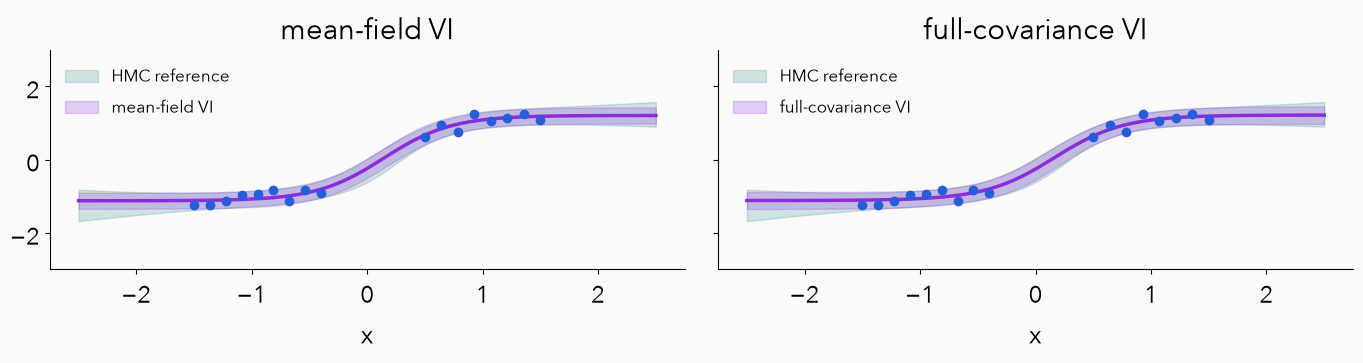

In [45]:
prior_mvn = dist.MultivariateNormal(torch.zeros(7), torch.eye(7))
rows, cols = torch.tril_indices(7, 7, -1)
def full_q(mu, log_diag, off):
    L = torch.diag(log_diag.exp()).index_put((rows, cols), off)   # lower-triangular, positive diagonal
    return dist.MultivariateNormal(mu, scale_tril=L)
# Start from the mean-field answer (off-diagonals 0), then let q tilt: the full family contains the
# mean-field one, so from there the optimiser can only add what correlations buy.
torch.manual_seed(0)
mu_f = torch.nn.Parameter(q_vi.loc.clone()); log_diag = torch.nn.Parameter(q_vi.scale.log().clone())
off = torch.nn.Parameter(torch.zeros(21))
opt_full = torch.optim.Adam([mu_f, log_diag, off], lr=.01)
for step in range(4000):
    q = full_q(mu_f, log_diag, off)
    theta_s = q.rsample((64,))
    elbo = bnn_log_lik(theta_s).mean() - dist.kl_divergence(q, prior_mvn)
    opt_full.zero_grad(); (-elbo).backward(); opt_full.step()
with torch.no_grad():
    q_full = full_q(mu_f, log_diag, off)
    torch.manual_seed(20_000)
    full_ell = number(bnn_log_lik(q_full.sample((20_000,))).mean())
    full_kl = number(dist.kl_divergence(q_full, prior_mvn))
    torch.manual_seed(14)
    F_full = net(q_full.sample((4000,)), x_grid)
full_elbo = full_ell - full_kl
full_sd = (F_full.var(0) + noise_sd ** 2).sqrt()
cov_full = q_full.covariance_matrix
corr_full = cov_full / torch.outer(cov_full.diagonal().sqrt(), cov_full.diagonal().sqrt())
off_corr = corr_full.masked_fill(torch.eye(7, dtype=bool), 0)
i_c, j_c = divmod(int(off_corr.abs().argmax()), 7)
assert full_elbo > vi_run["elbo"] and full_elbo < log_evidence_bnn
fixtures["story"]["bnn"]["vi_full"] = dict(start="the mean-field answer, off-diagonals 0", steps=4000, draws=64, lr=.01,
    mu=q_full.loc.tolist(), sd=cov_full.diagonal().sqrt().tolist(), corr=corr_full.tolist(),
    largest_corr=dict(pair=[bnn_names[i_c], bnn_names[j_c]], value=number(off_corr[i_c, j_c])),
    elbo=full_elbo, expected_log_lik=full_ell, kl_prior=full_kl, gap=log_evidence_bnn - full_elbo,
    mean=F_full.mean(0).tolist(), sd_pred=full_sd.tolist())
print(f"ELBO: mean-field {vi_run['elbo']:.2f}, full covariance {full_elbo:.2f}; log p(D) ≈ {log_evidence_bnn:.2f}")
print(f"largest correlation: {bnn_names[i_c]} and {bnn_names[j_c]}, {number(off_corr[i_c, j_c]):.2f}")
print("predictive sd at x = −2.5, 0, 2.5: mean-field", [round(number(vi_sd[i]), 3) for i in (0, 60, 120)],
      "· full", [round(number(full_sd[i]), 3) for i in (0, 60, 120)], "· HMC", [round(number(post_sd[i]), 3) for i in (0, 60, 120)])
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (mean, sd, title) in zip(axes, [(F_vi.mean(0), vi_sd, "mean-field VI"), (F_full.mean(0), full_sd, "full-covariance VI")]):
    ax.fill_between(x_grid, F_post.mean(0) - 2 * post_sd, F_post.mean(0) + 2 * post_sd, color=C["p"], alpha=.18, label="HMC reference")
    ax.fill_between(x_grid, mean - 2 * sd, mean + 2 * sd, color=C["q"], alpha=.22, label=title)
    ax.plot(x_grid, mean, color=C["q"]); ax.scatter(x_train, y_train, color=C["data"], zorder=3)
    ax.set(xlabel="x", ylim=(-3, 3), title=title); ax.legend(frameon=False, fontsize=12)
savefig("bnn-vi-families")

### 5.2 Wrap-up: retrieve the method

Slides: [5.2 Six obstacles, six tools](https://nipunbatra.github.io/generative/lectures/lecture1/#five-tools/1)

Before revealing the answers, answer these in your own words:

1. For KL(q‖p), where do the samples come from?
2. What changes during VI: data, model, posterior, variational parameters, or all of them?
3. Why can we optimise without knowing the evidence?
4. Does an ELBO estimate above the evidence disprove the lower-bound identity?
5. Does a high or stable ELBO prove that q equals the posterior?

**Answers.** Draw from q. In the fixed-model inference problem, update ψ; data, model and exact posterior stay fixed. The evidence is constant in ψ. A finite-sample estimate is not the exact expectation. Improvement is not an exact-recovery certificate.

**Transfer:** for an image model $p_\theta(x,z)$ with fixed θ, specify $q_\psi(z)$ and maximise $\mathbb E_q[\log p_\theta(x,z)-\log q_\psi(z)]$. Lecture 2 will learn model parameters and share an encoder across observations.

## Appendix · KL by hand: grades in two runs of a course

Appendix slides: [two runs of the course](https://nipunbatra.github.io/generative/lectures/lecture1/?all#grades/1) · [find the function](https://nipunbatra.github.io/generative/lectures/lecture1/?all#grades-f/1) · [weight by p](https://nipunbatra.github.io/generative/lectures/lecture1/?all#grades-kl/1) · [swap the reference](https://nipunbatra.github.io/generative/lectures/lecture1/?all#asymmetry/1) · [sample grades](https://nipunbatra.github.io/generative/lectures/lecture1/?all#mc-grades/1)

The build-up follows [ritvikmath, “The KL Divergence: Data Science Basics”](https://www.youtube.com/watch?v=q0AkK8aYbLY). Last year’s grades are the reference $q$: 10% A, 40% B, 50% C. This year’s are $p$: 40%, 10%, 50%.

1. Compare grade by grade with **ratios** $p/q$: $4,\ \tfrac14,\ 1$.
2. Ask what a ratio should count for: $f(1)=0$, a fourfold rise and a fourfold fall should cancel, and changes should add up, $f(ab)=f(a)+f(b)$. Only the **logarithm** does all three: $1.386,\ -1.386,\ 0$.
3. A plain average of the logs is $0$ here, though the years differ. **Weight** each grade by how common it is this year: $\mathrm{KL}(p\|q)=\sum_x p(x)\log\frac{p(x)}{q(x)}\approx0.42$ nats.

With the natural log the unit is the nat; with $\log_2$ it is the bit. Swap the reference year and the value changes: KL is not symmetric.

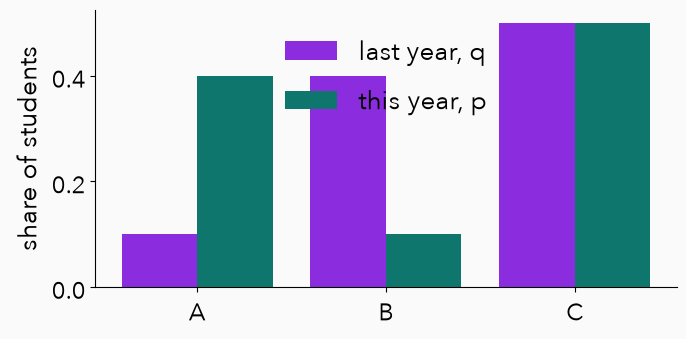

Grades: KL(p||q) = 0.4159 nats = 0.6000 bits (library 0.4159); plain average of the logs 0.0000
Swapped reference: KL(this||last) = 0.6365, KL(last||this) = 0.2976


In [46]:
grade_names = ["A", "B", "C"]
grade_q = np.array([.1, .4, .5])  # last year
grade_p = np.array([.4, .1, .5])  # this year
grade_ratio = grade_p / grade_q
grade_terms = grade_p * np.log(grade_ratio)
grade_kl = float(grade_terms.sum())
library = number(dist.kl_divergence(dist.Categorical(probs=torch.tensor(grade_p)),
                                    dist.Categorical(probs=torch.tensor(grade_q))))
assert abs(grade_kl - library) < 1e-12
# A second pair of years where the two directions differ: almost no A's last year, many this year
swap_q, swap_p = np.array([.01, .49, .5]), np.array([.25, .25, .5])
swap_terms_pq, swap_terms_qp = swap_p * np.log(swap_p / swap_q), swap_q * np.log(swap_q / swap_p)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
xs = np.arange(3)
ax.bar(xs - .2, grade_q, .4, color=C["q"], label="last year, q")
ax.bar(xs + .2, grade_p, .4, color=C["p"], label="this year, p")
ax.set_xticks(xs, grade_names); ax.set(ylabel="share of students"); ax.legend(frameon=False)
plt.show()
fixtures["story"]["grades"] = dict(names=grade_names, q=grade_q.tolist(), p=grade_p.tolist(),
    ratio=grade_ratio.tolist(), log_ratio=np.log(grade_ratio).tolist(), terms=grade_terms.tolist(),
    kl=grade_kl, kl_bits=grade_kl / math.log(2), ratio_mean=float(grade_ratio.mean()),
    log_ratio_mean=float(np.log(grade_ratio).mean()), geometric_mean_ratio=math.exp(grade_kl),
    swap=dict(q=swap_q.tolist(), p=swap_p.tolist(), kl_pq=float(swap_terms_pq.sum()), kl_qp=float(swap_terms_qp.sum()),
              terms_pq=swap_terms_pq.tolist(), terms_qp=swap_terms_qp.tolist()))
print(f"Grades: KL(p||q) = {grade_kl:.4f} nats = {grade_kl / math.log(2):.4f} bits (library {library:.4f}); "
      f"plain average of the logs {np.log(grade_ratio).mean():.4f}")
print(f"Swapped reference: KL(this||last) = {swap_terms_pq.sum():.4f}, KL(last||this) = {swap_terms_qp.sum():.4f}")

S =     10: shares A/B/C = [0.5 0.1 0.4], average log ratio = 0.5545  (exact 0.4159)
S =    100: shares A/B/C = [0.47 0.1  0.43], average log ratio = 0.5129  (exact 0.4159)
S =  1,000: shares A/B/C = [0.427 0.093 0.48 ], average log ratio = 0.4630  (exact 0.4159)
S = 10,000: shares A/B/C = [0.409 0.101 0.49 ], average log ratio = 0.4279  (exact 0.4159)


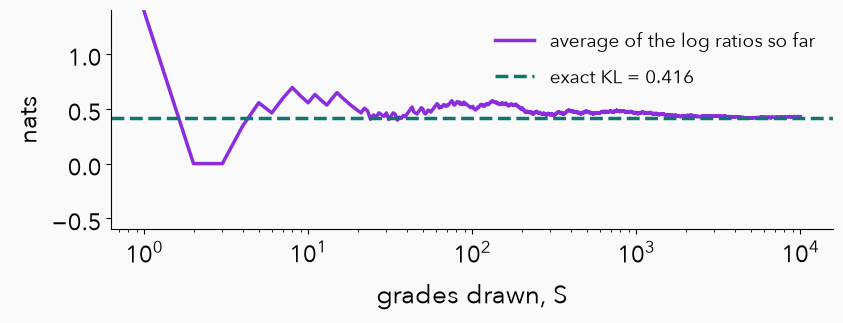

In [47]:
rng = np.random.default_rng(11)
draws = rng.choice(3, size=10_000, p=grade_p)          # grades drawn from this year's distribution
log_ratio = np.log(grade_p / grade_q)                    # one log ratio per grade
running = np.cumsum(log_ratio[draws]) / np.arange(1, len(draws) + 1)
for S in [10, 100, 1_000, 10_000]:
    shares = np.bincount(draws[:S], minlength=3) / S
    print(f"S = {S:6,}: shares A/B/C = {shares.round(3)}, average log ratio = {running[S - 1]:.4f}  (exact {grade_kl:.4f})")
fixtures["story"]["grades_sampling"] = dict(seed=11, sizes=[10, 100, 1000, 10000],
    estimates=[float(running[S - 1]) for S in [10, 100, 1000, 10000]])
fig, ax = plt.subplots(figsize=(8.8, 3.6))
ax.semilogx(np.arange(1, len(draws) + 1), running, color=C["q"], label="average of the log ratios so far")
ax.axhline(grade_kl, color=C["p"], ls="--", label=f"exact KL = {grade_kl:.3f}")
ax.set(xlabel="grades drawn, S", ylabel="nats", ylim=(-.6, 1.4)); ax.legend(frameon=False, fontsize=14)
savefig("grades-sampling")

## Optional depth

Slides: the optional slides follow the main route ([first optional slide](https://nipunbatra.github.io/generative/lectures/lecture1/?all#evidence-mc/1)).

#### KL is the rate at which evidence piles up

Optional slide: [a KL value is how fast evidence piles up](https://nipunbatra.github.io/generative/lectures/lecture1/?all#coin-evidence/1). A coin lands heads 80% of the time. Each toss favours “0.8” over “fair” by $\mathrm{KL}(0.8\|0.5)\approx0.19$ nats on average, so after $n$ tosses the likelihood ratio is typically $e^{0.19n}$.

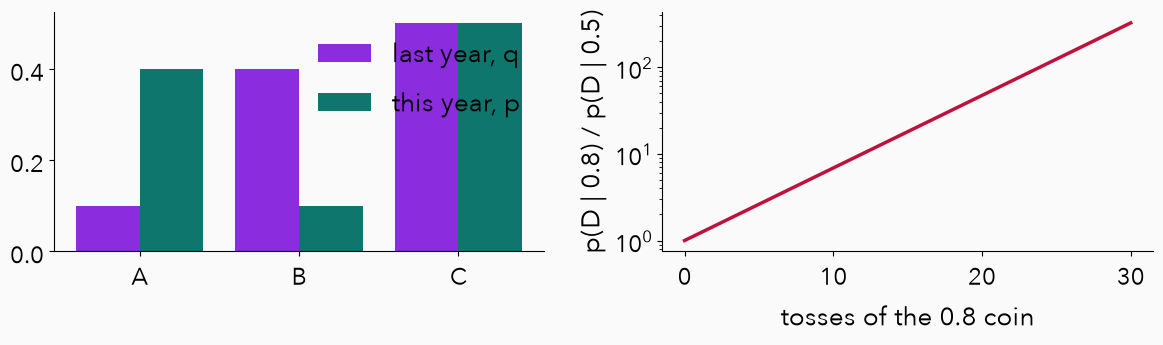

Coins: KL(0.8 || 0.5) = 0.1927, reverse 0.2231; e^(10 KL) = 6.9, e^(30 KL) = 325; simulated mean log ratio after 30 = 5.780 (30 KL = 5.782)


In [48]:
coin_08, coin_05 = dist.Bernoulli(torch.tensor(.8)), dist.Bernoulli(torch.tensor(.5))
kl_coin = number(dist.kl_divergence(coin_08, coin_05))
kl_coin_reverse = number(dist.kl_divergence(coin_05, coin_08))
torch.manual_seed(5)
toss_sim = (torch.rand(20_000, 30) < .8).double()
llr = (toss_sim * math.log(.8 / .5) + (1 - toss_sim) * math.log(.2 / .5)).cumsum(1)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
xs = np.arange(3)
axes[0].bar(xs - .2, grade_q, .4, color=C["q"], label="last year, q")
axes[0].bar(xs + .2, grade_p, .4, color=C["p"], label="this year, p")
axes[0].set_xticks(xs, grade_names); axes[0].legend(frameon=False)
n = np.arange(31)
axes[1].semilogy(n, np.exp(n * kl_coin), color=C["loss"])
axes[1].set(xlabel="tosses of the 0.8 coin", ylabel="p(D | 0.8) / p(D | 0.5)")
savefig("kl-intuition")
fixtures["story"]["coinkl"] = dict(kl=kl_coin, reverse=kl_coin_reverse,
    x10=math.exp(10 * kl_coin), x30=math.exp(30 * kl_coin),
    simulated_mean_llr_30=float(llr[:, -1].mean()), simulated_sequences=20_000, simulation_seed=5)
print(f"Coins: KL(0.8 || 0.5) = {kl_coin:.4f}, reverse {kl_coin_reverse:.4f}; "
      f"e^(10 KL) = {math.exp(10 * kl_coin):.1f}, e^(30 KL) = {math.exp(30 * kl_coin):.0f}; "
      f"simulated mean log ratio after 30 = {float(llr[:, -1].mean()):.3f} (30 KL = {30 * kl_coin:.3f})")

#### A better KL estimator: never negative, lower variance

Optional slide: [a KL estimator that is never negative](https://nipunbatra.github.io/generative/lectures/lecture1/?all#kl-estimators/1). From the end of Jia-Bin Huang’s video and John Schulman’s note [“Approximating KL divergence”](http://joschu.net/blog/kl-approx.html). For $\mathrm{KL}(q\|p)$ with draws from $q$, write $r=p(\theta)/q(\theta)$. The plain estimator averages $-\log r$, and a few draws can make it negative. Since $\mathbb E_q[r]=1$, adding $r-1$ changes nothing on average, and $r-1-\log r\ge0$ for every single draw: the tangent-line fact of Section 4.1. It also has lower variance when $r$ stays bounded, as here ($p$ narrower than $q$); if $p$ has heavier tails than $q$, $r$ can have infinite variance and the plain estimator is safer.

In [49]:
def kl_estimates(q, p, S, seed):
    torch.manual_seed(seed)
    th = q.sample((S,))
    log_r = p.log_prob(th) - q.log_prob(th)
    return number((-log_r).mean()), number((log_r.exp() - 1 - log_r).mean())
# p narrower than q keeps the ratio r = p/q bounded under q; with heavier-tailed p, r − 1 − log r can have infinite variance.
q_est, p_est = dist.Normal(0., 2.), dist.Normal(.5, 1.5)
exact_q1 = number(dist.kl_divergence(q_est, p_est))
estimator_rows = []
for S in [5, 10, 100, 1000]:
    k1, k3 = np.array([kl_estimates(q_est, p_est, S, 5000 + j) for j in range(400)]).T
    estimator_rows.append(dict(S=S, plain_mean=float(k1.mean()), plain_sd=float(k1.std()), plain_negative=float((k1 < 0).mean()),
                               better_mean=float(k3.mean()), better_sd=float(k3.std()), better_negative=float((k3 < 0).mean())))
    print(f"S = {S:5d}: plain mean {k1.mean():.3f} sd {k1.std():.3f} ({(k1 < 0).mean():.0%} negative) · "
          f"r − 1 − log r mean {k3.mean():.3f} sd {k3.std():.3f} ({(k3 < 0).mean():.0%} negative) · exact {exact_q1:.3f}")
fixtures["story"]["estimators"] = dict(pair="q = N(0, 2²) against p = N(0.5, 1.5²)", exact=exact_q1, repeats=400, rows=estimator_rows)

S =     5: plain mean 0.171 sd 0.299 (34% negative) · r − 1 − log r mean 0.157 sd 0.154 (0% negative) · exact 0.157


S =    10: plain mean 0.160 sd 0.219 (24% negative) · r − 1 − log r mean 0.157 sd 0.119 (0% negative) · exact 0.157


S =   100: plain mean 0.162 sd 0.072 (0% negative) · r − 1 − log r mean 0.158 sd 0.039 (0% negative) · exact 0.157


S =  1000: plain mean 0.157 sd 0.023 (0% negative) · r − 1 − log r mean 0.156 sd 0.013 (0% negative) · exact 0.157


#### An independent integral check

The scalar Beta example also permits numerical integration. This is an approximate quadrature check, labelled separately from the analytic formula. At endpoints the integrands have zero limits for these chosen shape parameters.

In [50]:
grid=torch.linspace(0,1,100001)
interior=grid[1:-1]
quad_checks=[]
for row in coin_candidates:
    q=dist.Beta(row["a"],row["b"])
    density=q.log_prob(interior).exp()
    integrand=density*(log_joint(interior)-q.log_prob(interior))
    padded=torch.cat([torch.zeros(1),integrand,torch.zeros(1)])
    numerical=torch.trapezoid(padded,grid)
    error=abs(number(numerical)-row["elbo"])
    assert error<1e-8
    quad_checks.append(dict(a=row["a"],b=row["b"],numerical_elbo=number(numerical),error=error))
fixtures["checks"]={"coin_quadrature":quad_checks,
    "normal_analytic_vs_library":True,"normal_gradient_finite_difference":True,
    "positive_scales_and_shapes":True,"fixed_noise_gradient_check":True,
    "coin_direct_elbo_identity":True,"coin_training_final_gap":coin_trace[-1]["posterior_kl"]}
print(quad_checks)

[{'a': 10.0, 'b': 10.0, 'numerical_elbo': -22.020154134036773, 'error': 3.552713678800501e-14}, {'a': 30.0, 'b': 20.0, 'numerical_elbo': -21.448585391137854, 'error': 8.526512829121202e-14}, {'a': 22.0, 'b': 16.0, 'numerical_elbo': -21.397241822312157, 'error': 4.973799150320701e-14}]


#### Count data versus an ordered sequence

If the observation were only the count “17 heads out of 30”, the likelihood would include $\binom{30}{17}$. This constant would add to both log evidence and ELBO. The posterior and the posterior-KL gap would be unchanged. We have used the ordered-sequence convention consistently.

In [51]:
log_choose=math.lgamma(31)-math.lgamma(18)-math.lgamma(14)
print("Log binomial coefficient:",log_choose)
print("Count-data log evidence:",number(log_evidence)+log_choose)
print("Ordered-sequence log evidence:",number(log_evidence))
fixtures["coin"]["count_convention_comparison"]={"log_binomial_coefficient":log_choose,
    "count_log_evidence":number(log_evidence)+log_choose}
fixtures["plots"]={
    "normal":{"x":theta_grid.tolist(),"p":p.log_prob(theta_grid).exp().tolist(),
        "q1":q1.log_prob(theta_grid).exp().tolist(),"q2":q2.log_prob(theta_grid).exp().tolist(),
        "updated":dist.Normal(.25,2.).log_prob(theta_grid).exp().tolist(),
        "snapshots":{str(s):dist.Normal(normal_trace[s]["mu"],normal_trace[s]["sigma"]).log_prob(theta_grid).exp().tolist()
                     for s in [0,10,30,150]}},
    "mixture":{"x":xx.tolist(),"p":mixture.log_prob(xx).exp().tolist(),
        "q1":mix_q1.log_prob(xx).exp().tolist(),"q2":mix_q2.log_prob(xx).exp().tolist()},
    "coin":{"x":rr.tolist(),"prior":prior.log_prob(rr).exp().tolist(),
        "posterior":posterior.log_prob(rr).exp().tolist(),
        "candidates":[dist.Beta(row["a"],row["b"]).log_prob(rr).exp().tolist() for row in coin_candidates],
        "snapshots":{str(s):dist.Beta(coin_trace[s]["a"],coin_trace[s]["b"]).log_prob(rr).exp().tolist()
                     for s in [0,20,100,600]}}
}
(OUT/"data"/"science.json").write_text(json.dumps(fixtures,indent=2,allow_nan=False)+"\n")
(OUT/"qa"/"notebook-checks.json").write_text(json.dumps({
    "status":"passed","runtime":fixtures["provenance"],"checks":fixtures["checks"],
    "executed_code_cells":"all cells in saved notebook",
    "training":"toy CPU optimisation; measured trajectories, not schematic",
},indent=2,allow_nan=False)+"\n")
print("Saved full-precision fixtures and verification report.")

Log binomial coefficient: 18.600999045569846
Count-data log evidence: -2.7962427767422575
Ordered-sequence log evidence: -21.397241822312104


Saved full-precision fixtures and verification report.


## Sources and adaptation

- Nipun Batra, [PML 2023 VI notebook](https://github.com/nipunbatra/pml-teaching/blob/master/notebooks/variational-inference.ipynb): Gaussian, mixture, reparameterisation and coin teaching sequence.
- [PyTorch distribution documentation](https://pytorch.org/docs/stable/distributions.html): distribution parameters, `sample`, `rsample` and KL API.
- Figurnov, Mohamed and Mnih, [Implicit Reparameterization Gradients](https://arxiv.org/abs/1805.08498): differentiable sampling beyond the location–scale Gaussian form.

This is a new standalone implementation. It removes hidden training helpers, stale computation-graph references and unsafe unconstrained positive parameters from the historical notebook. Numerical results here come from the saved execution, with the configurations above.
- ritvikmath, [“The KL Divergence: Data Science Basics”](https://www.youtube.com/watch?v=q0AkK8aYbLY): the grades build-up in 2.1.
- Aurélien Géron, [“A Short Introduction to Entropy, Cross-Entropy and KL-Divergence”](https://www.youtube.com/watch?v=ErfnhcEV1O8): the coding story in 2.2.
- PyTorch, [`torch/distributions/kl.py`](https://github.com/pytorch/pytorch/blob/main/torch/distributions/kl.py): the closed forms in 2.4.
- Lilian Weng, [“From Autoencoder to Beta-VAE”](https://lilianweng.github.io/posts/2018-08-12-vae/): stochastic and deterministic nodes in the reparameterisation picture, 3.5.
- Gregory Gundersen, [“The ELBO in Variational Inference”](https://www.gregorygundersen.com/blog/2021/04/16/variational-inference/): the derivation in 4.1.